In [2]:
#Cell 1
import torch

# Check whether a GPU is available
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

# If a GPU is available, print its name
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [3]:
#Cell 2
# Import libraries

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import random
import os
import copy
import time

from torch.utils.data import DataLoader, Subset


In [4]:
#Cell 3
# Download CIFAR-10 training and test datasets

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Get the names of the 10 image categories
class_names = train_dataset.classes

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Categories:", class_names)


100%|██████████| 170M/170M [25:51<00:00, 110kB/s]


Training images: 50000
Testing images: 10000
Number of classes: 10
Categories: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


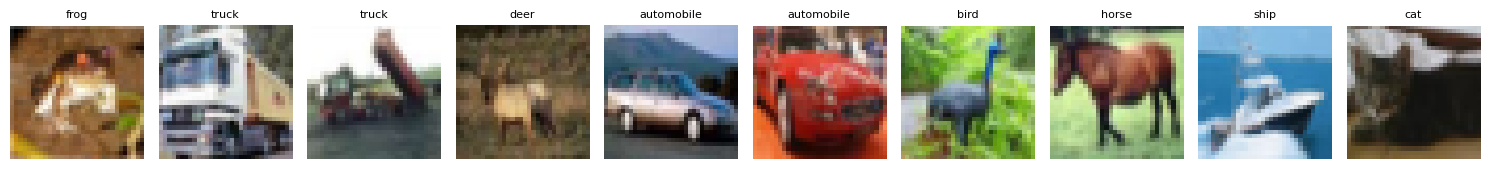

In [5]:
#Cell 4
# Display some sample CIFAR-10 images

# Get 10 images from the training dataset
images = [train_dataset[i][0] for i in range(10)]
labels = [train_dataset[i][1] for i in range(10)]

# Create a row of 10 images
plt.figure(figsize=(15, 3))

for i in range(10):
    plt.subplot(1, 10, i + 1)

    # Convert image dimensions for matplotlib
    image = images[i].permute(1, 2, 0)

    plt.imshow(image)
    plt.title(class_names[labels[i]], fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [6]:
#Cell 5
# Set a fixed random seed so we get the same split every time
torch.manual_seed(42)

# Split the 50,000 training images into 45,000 and 5,000
train_dataset_split, val_dataset = torch.utils.data.random_split(
    train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

# Create a smaller dataset containing 10% of the training images
small_train_dataset, _ = torch.utils.data.random_split(
    train_dataset_split,
    [4500, 40500],
    generator=torch.Generator().manual_seed(42)
)

# Print the sizes of each dataset
print("Full training dataset:", len(train_dataset_split))
print("Validation dataset:", len(val_dataset))
print("10% training dataset:", len(small_train_dataset))
print("Test dataset:", len(test_dataset))


Full training dataset: 45000
Validation dataset: 5000
10% training dataset: 4500
Test dataset: 10000


In [7]:
#Cell 6
# Set the batch size
batch_size = 128

# Create a DataLoader for the full training dataset
train_loader = DataLoader(
    train_dataset_split,
    batch_size=batch_size,
    shuffle=True
)

# Create a DataLoader for the 10% training dataset
small_train_loader = DataLoader(
    small_train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# Create a DataLoader for validation
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Create a DataLoader for testing
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Full training batches:", len(train_loader))
print("10% training batches:", len(small_train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Full training batches: 352
10% training batches: 36
Validation batches: 40
Test batches: 79


In [8]:
#Cell 7
# Get one batch of training images
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])


Image batch shape: torch.Size([128, 3, 32, 32])
Label batch shape: torch.Size([128])
First 10 labels: tensor([3, 6, 1, 5, 6, 1, 9, 6, 3, 4])


In [9]:
#Cell 8
# Define a CNN from scratch

class SmallCNN(nn.Module):
    def __init__(self):
        super(SmallCNN, self).__init__()

        # First convolutional block
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(64)

        # Second convolutional block
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(128)

        # Third convolutional block
        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(256)

        # Pooling layer
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Dropout layer
        self.dropout = nn.Dropout(0.5)

        # Final classification layer
        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        # First block
        x = self.pool(torch.relu(self.bn1(self.conv1(x))))

        # Second block
        x = self.pool(torch.relu(self.bn2(self.conv2(x))))

        # Third block
        x = self.pool(torch.relu(self.bn3(self.conv3(x))))

        # Reduce each feature map to one value
        x = nn.functional.adaptive_avg_pool2d(x, (1, 1))

        # Flatten the output
        x = torch.flatten(x, 1)

        # Apply dropout
        x = self.dropout(x)

        # Predict one of the 10 categories
        x = self.fc(x)

        return x


In [10]:
#Cell 9
# Create the CNN
model = SmallCNN()

# Move the model to the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Test the model with one batch of images
sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)
print("Device:", device)
print("Total trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


Input shape: torch.Size([128, 3, 32, 32])
Output shape: torch.Size([128, 10])
Device: cuda
Total trainable parameters: 374282


In [11]:
# Cell 10: Import TensorBoard for experiment tracking

from torch.utils.tensorboard import SummaryWriter

print("TensorBoard is ready!")


TensorBoard is ready!


In [12]:

# Cell 11: Define the training and validation functions

def train_model(model, train_loader, val_loader, criterion,
                optimizer, epochs, run_name):

    # Create a TensorBoard log for this experiment
    writer = SummaryWriter(log_dir=f"runs/{run_name}")

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):

        # -------------------------
        # Training phase
        # -------------------------
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Clear previous gradients
            optimizer.zero_grad()

            # Make predictions
            outputs = model(images)

            # Calculate the loss
            loss = criterion(outputs, labels)

            # Calculate gradients
            loss.backward()

            # Update model weights
            optimizer.step()

            train_loss += loss.item() * images.size(0)

            # Find the predicted categories
            _, predicted = torch.max(outputs, 1)

            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

        train_loss = train_loss / train_total
        train_accuracy = 100 * train_correct / train_total

        # -------------------------
        # Validation phase
        # -------------------------
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)

                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss = val_loss / val_total
        val_accuracy = 100 * val_correct / val_total

        # Save results in the history dictionary
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        # Record results in TensorBoard
        writer.add_scalar("Loss/Training", train_loss, epoch + 1)
        writer.add_scalar("Loss/Validation", val_loss, epoch + 1)
        writer.add_scalar("Accuracy/Training", train_accuracy, epoch + 1)
        writer.add_scalar("Accuracy/Validation", val_accuracy, epoch + 1)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Training Loss: {train_loss:.4f} "
            f"Training Accuracy: {train_accuracy:.2f}% "
            f"Validation Loss: {val_loss:.4f} "
            f"Validation Accuracy: {val_accuracy:.2f}%"
        )

    writer.close()

    return history


In [13]:
# Cell 12: Set up reproducibility

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"Random seed set to {seed}!")

# We will start with our first seed
set_seed(42)


Random seed set to 42!


In [14]:

# Cell 13: Initialize our first CNN experiment

set_seed(42)

cnn_model = SmallCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

print("Model initialized!")
print("Training images:", len(train_dataset_split))
print("Validation images:", len(val_dataset))
print("Epochs: 10")
print("Random seed: 42")


Random seed set to 42!
Model initialized!
Training images: 45000
Validation images: 5000
Epochs: 10
Random seed: 42


In [15]:

# Cell 14: Train our first CNN from scratch

cnn_history = train_model(
    model=cnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=10,
    run_name="CNN_Full_Seed42"
)

print("Training completed!")


Epoch [1/10] Training Loss: 1.4933 Training Accuracy: 45.05% Validation Loss: 1.4631 Validation Accuracy: 50.16%
Epoch [2/10] Training Loss: 1.2109 Training Accuracy: 56.33% Validation Loss: 1.2609 Validation Accuracy: 53.80%
Epoch [3/10] Training Loss: 1.0986 Training Accuracy: 60.91% Validation Loss: 1.4745 Validation Accuracy: 47.22%
Epoch [4/10] Training Loss: 1.0158 Training Accuracy: 63.96% Validation Loss: 1.2956 Validation Accuracy: 57.96%
Epoch [5/10] Training Loss: 0.9660 Training Accuracy: 65.94% Validation Loss: 1.0022 Validation Accuracy: 64.30%
Epoch [6/10] Training Loss: 0.9060 Training Accuracy: 68.02% Validation Loss: 0.9814 Validation Accuracy: 65.10%
Epoch [7/10] Training Loss: 0.8629 Training Accuracy: 69.72% Validation Loss: 1.3291 Validation Accuracy: 55.14%
Epoch [8/10] Training Loss: 0.8215 Training Accuracy: 71.21% Validation Loss: 0.9996 Validation Accuracy: 65.86%
Epoch [9/10] Training Loss: 0.7904 Training Accuracy: 72.45% Validation Loss: 0.9396 Validation 

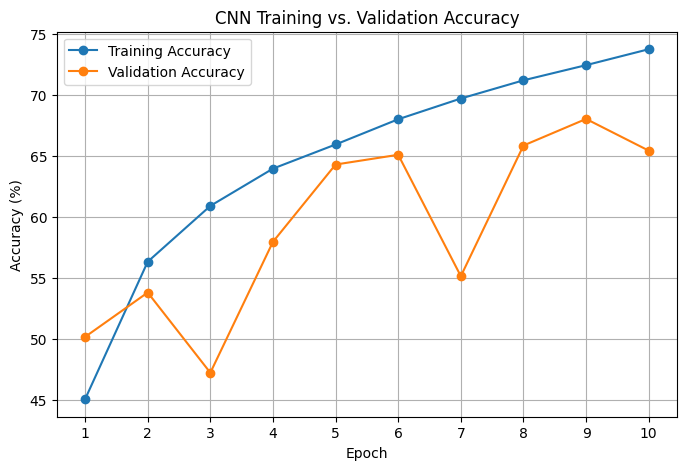

In [16]:

# Cell 15: Plot training and validation accuracy

epochs_range = range(1, 11)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    cnn_history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    cnn_history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Training vs. Validation Accuracy")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)
plt.show()

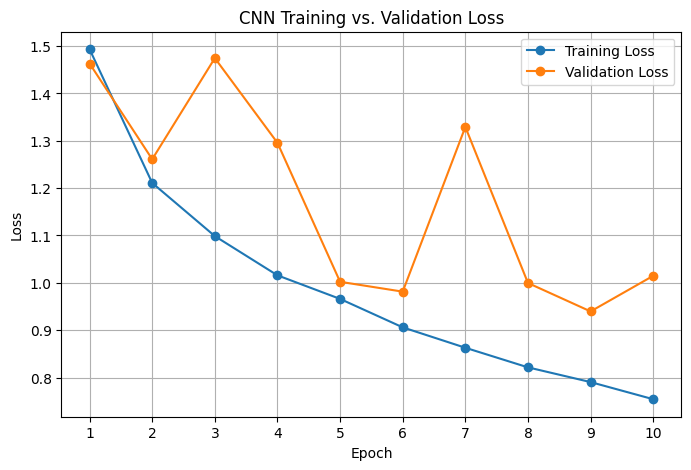

In [17]:

# Cell 16: Plot training and validation loss

epochs_range = range(1, 11)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    cnn_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    cnn_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs. Validation Loss")
plt.xticks(epochs_range)
plt.legend()
plt.grid(True)
plt.show()


In [18]:

# Cell 17: Evaluate our CNN on the test dataset

cnn_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = cnn_model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 65.08%
Correct predictions: 6508/10000


In [19]:
# Cell 18: Check our new runtime

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [20]:
# Cell 19: Check whether CIFAR-10 is still downloaded

import os

print("CIFAR-10 folder exists:", os.path.exists("./data/cifar-10-batches-py"))

CIFAR-10 folder exists: True


In [16]:

# Cell 20: Reload CIFAR-10 from existing files or download if needed

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

class_names = train_dataset.classes

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Categories:", class_names)

100%|██████████| 170M/170M [39:35<00:00, 71.8kB/s]


Training images: 50000
Testing images: 10000
Number of classes: 10
Categories: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [17]:

# Cell 21: Recreate our dataset splits

torch.manual_seed(42)

train_dataset_split, val_dataset = torch.utils.data.random_split(
    train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

small_train_dataset, _ = torch.utils.data.random_split(
    train_dataset_split,
    [4500, 40500],
    generator=torch.Generator().manual_seed(42)
)

print("Full training dataset:", len(train_dataset_split))
print("Validation dataset:", len(val_dataset))
print("10% training dataset:", len(small_train_dataset))
print("Test dataset:", len(test_dataset))


Full training dataset: 45000
Validation dataset: 5000
10% training dataset: 4500
Test dataset: 10000


In [18]:

# Cell 22: Recreate our DataLoaders

batch_size = 128

train_loader = DataLoader(
    train_dataset_split,
    batch_size=batch_size,
    shuffle=True
)

small_train_loader = DataLoader(
    small_train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Full training batches:", len(train_loader))
print("10% training batches:", len(small_train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Full training batches: 352
10% training batches: 36
Validation batches: 40
Test batches: 79


In [19]:

# Cell 23: Load pretrained ResNet-18

resnet_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

print("ResNet-18 loaded successfully!")
print("Original output classes:", resnet_model.fc.out_features)


ResNet-18 loaded successfully!
Original output classes: 1000


In [20]:

# Cell 24: Prepare images for ResNet-18

resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("ResNet-18 image transformations created!")


ResNet-18 image transformations created!


In [21]:

# Cell 25: Create datasets for ResNet-18

resnet_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=resnet_transform
)

resnet_test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=resnet_transform
)

print("ResNet-18 training images:", len(resnet_train_dataset))
print("ResNet-18 testing images:", len(resnet_test_dataset))


ResNet-18 training images: 50000
ResNet-18 testing images: 10000


In [22]:

# Cell 26: Create matching ResNet-18 data splits

resnet_train_split = Subset(
    resnet_train_dataset,
    train_dataset_split.indices
)

resnet_val_split = Subset(
    resnet_train_dataset,
    val_dataset.indices
)

# Recreate the same 10% training subset
small_indices = [
    train_dataset_split.indices[i]
    for i in small_train_dataset.indices
]

resnet_small_train_split = Subset(
    resnet_train_dataset,
    small_indices
)

print("Full training images:", len(resnet_train_split))
print("Validation images:", len(resnet_val_split))
print("10% training images:", len(resnet_small_train_split))


Full training images: 45000
Validation images: 5000
10% training images: 4500


In [23]:

# Cell 27: Create ResNet-18 DataLoaders

resnet_batch_size = 64

resnet_train_loader = DataLoader(
    resnet_train_split,
    batch_size=resnet_batch_size,
    shuffle=True
)

resnet_small_train_loader = DataLoader(
    resnet_small_train_split,
    batch_size=resnet_batch_size,
    shuffle=True
)

resnet_val_loader = DataLoader(
    resnet_val_split,
    batch_size=resnet_batch_size,
    shuffle=False
)

resnet_test_loader = DataLoader(
    resnet_test_dataset,
    batch_size=resnet_batch_size,
    shuffle=False
)

print("Full training batches:", len(resnet_train_loader))
print("10% training batches:", len(resnet_small_train_loader))
print("Validation batches:", len(resnet_val_loader))
print("Test batches:", len(resnet_test_loader))


Full training batches: 704
10% training batches: 71
Validation batches: 79
Test batches: 157


In [24]:

# Cell 28: Freeze pretrained ResNet-18 layers

# Freeze all existing ResNet-18 parameters
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace the final layer with a new layer for 10 CIFAR-10 classes
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    10
)

# Move the model to the GPU
resnet_model = resnet_model.to(device)

# Count trainable parameters
trainable_params = sum(
    param.numel()
    for param in resnet_model.parameters()
    if param.requires_grad
)

print("Frozen feature extractor prepared!")
print("Number of trainable parameters:", trainable_params)
print("Number of output classes:", resnet_model.fc.out_features)


Frozen feature extractor prepared!
Number of trainable parameters: 5130
Number of output classes: 10


In [25]:

# Cell 29: Set up the loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    resnet_model.fc.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate: 0.001")


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001


In [26]:

# Cell 30: Test ResNet-18 with one batch

resnet_model.eval()

images, labels = next(iter(resnet_train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = resnet_model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Device:", device)


Input shape: torch.Size([64, 3, 224, 224])
Output shape: torch.Size([64, 10])
Device: cuda


In [27]:

# Cell 31: Define the ResNet training function

def train_resnet(model, train_loader, val_loader,
                 criterion, optimizer, epochs, run_name):

    writer = SummaryWriter(log_dir=f"runs/{run_name}")

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):

        # Training
        model.train()
        model_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            model_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = model_loss / total
        train_accuracy = 100 * correct / total

        # Validation
        model.eval()
        val_loss_total = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_total += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss = val_loss_total / val_total
        val_accuracy = 100 * val_correct / val_total

        # Save results
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        writer.add_scalar("Loss/Train", train_loss, epoch + 1)
        writer.add_scalar("Loss/Validation", val_loss, epoch + 1)
        writer.add_scalar("Accuracy/Train", train_accuracy, epoch + 1)
        writer.add_scalar("Accuracy/Validation", val_accuracy, epoch + 1)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2f}%"
        )

    writer.close()

    return history

print("ResNet training function created successfully!")


ResNet training function created successfully!


In [34]:

# Cell 32: Train frozen ResNet-18 (Full Dataset, Seed 42)

set_seed(42)

resnet_history = train_resnet(
    model=resnet_model,
    train_loader=resnet_train_loader,
    val_loader=resnet_val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=10,
    run_name="ResNet_Frozen_Full_Seed42"
)

print("Frozen ResNet-18 training completed!")


Random seed set to 42!
Epoch 1/10 | Train Loss: 0.8597 | Train Acc: 71.92% | Val Loss: 0.6339 | Val Acc: 78.18%
Epoch 2/10 | Train Loss: 0.6261 | Train Acc: 78.57% | Val Loss: 0.5923 | Val Acc: 79.08%
Epoch 3/10 | Train Loss: 0.5924 | Train Acc: 79.44% | Val Loss: 0.5711 | Val Acc: 80.26%
Epoch 4/10 | Train Loss: 0.5768 | Train Acc: 80.05% | Val Loss: 0.5714 | Val Acc: 80.34%
Epoch 5/10 | Train Loss: 0.5645 | Train Acc: 80.48% | Val Loss: 0.5574 | Val Acc: 80.20%
Epoch 6/10 | Train Loss: 0.5648 | Train Acc: 80.45% | Val Loss: 0.5789 | Val Acc: 80.34%
Epoch 7/10 | Train Loss: 0.5546 | Train Acc: 80.76% | Val Loss: 0.5580 | Val Acc: 80.08%
Epoch 8/10 | Train Loss: 0.5532 | Train Acc: 80.88% | Val Loss: 0.5629 | Val Acc: 80.38%
Epoch 9/10 | Train Loss: 0.5474 | Train Acc: 81.04% | Val Loss: 0.5635 | Val Acc: 80.22%
Epoch 10/10 | Train Loss: 0.5451 | Train Acc: 80.95% | Val Loss: 0.5962 | Val Acc: 79.38%
Frozen ResNet-18 training completed!


In [35]:

# Cell 33: Evaluate frozen ResNet-18 on the test dataset

resnet_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

resnet_test_accuracy = 100 * correct / total

print(f"Test Accuracy: {resnet_test_accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 79.48%
Correct predictions: 7948/10000


In [36]:

# Cell 34: Prepare ResNet-18 for full fine-tuning

set_seed(42)

# Load a fresh pretrained ResNet-18
resnet_finetune_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace the final layer for CIFAR-10's 10 classes
resnet_finetune_model.fc = nn.Linear(
    resnet_finetune_model.fc.in_features,
    10
)

# Move the model to the GPU
resnet_finetune_model = resnet_finetune_model.to(device)

# Count all trainable parameters
trainable_params = sum(
    param.numel()
    for param in resnet_finetune_model.parameters()
    if param.requires_grad
)

print("Full fine-tuning model prepared!")
print("Trainable parameters:", trainable_params)
print("Output classes:", resnet_finetune_model.fc.out_features)


Random seed set to 42!
Full fine-tuning model prepared!
Trainable parameters: 11181642
Output classes: 10


In [37]:

# Cell 35: Configure full fine-tuning optimizer

finetune_criterion = nn.CrossEntropyLoss()

finetune_optimizer = optim.Adam(
    resnet_finetune_model.parameters(),
    lr=0.0001
)

print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.0001")
print("All ResNet-18 layers are trainable!")


Loss function: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.0001
All ResNet-18 layers are trainable!


In [38]:

# Cell 36: Test the full fine-tuning model

resnet_finetune_model.eval()

images, labels = next(iter(resnet_train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = resnet_finetune_model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Device:", device)


Input shape: torch.Size([64, 3, 224, 224])
Output shape: torch.Size([64, 10])
Device: cuda


In [39]:

# Cell 37: Define faster training with mixed precision

def train_resnet_fast(model, train_loader, val_loader,
                      criterion, optimizer, epochs, run_name):

    writer = SummaryWriter(log_dir=f"runs/{run_name}")
    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):

        model.train()
        train_loss_total = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss_total += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = train_loss_total / total
        train_accuracy = 100 * correct / total

        model.eval()
        val_loss_total = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16,
                    enabled=(device.type == "cuda")
                ):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss_total += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss = val_loss_total / val_total
        val_accuracy = 100 * val_correct / val_total

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        writer.add_scalar("Loss/Train", train_loss, epoch + 1)
        writer.add_scalar("Loss/Validation", val_loss, epoch + 1)
        writer.add_scalar("Accuracy/Train", train_accuracy, epoch + 1)
        writer.add_scalar("Accuracy/Validation", val_accuracy, epoch + 1)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2f}%"
        )

    writer.close()
    return history

print("Faster training function created successfully!")


Faster training function created successfully!


In [40]:

# Cell 38: Train ResNet-18 with full fine-tuning

set_seed(42)

finetune_history = train_resnet_fast(
    model=resnet_finetune_model,
    train_loader=resnet_train_loader,
    val_loader=resnet_val_loader,
    criterion=finetune_criterion,
    optimizer=finetune_optimizer,
    epochs=10,
    run_name="ResNet_Finetune_Full_Seed42"
)

print("Full fine-tuning training completed!")


Random seed set to 42!
Epoch 1/10 | Train Loss: 0.3435 | Train Acc: 88.68% | Val Loss: 0.1880 | Val Acc: 93.70%
Epoch 2/10 | Train Loss: 0.0993 | Train Acc: 96.85% | Val Loss: 0.2005 | Val Acc: 93.42%
Epoch 3/10 | Train Loss: 0.0496 | Train Acc: 98.49% | Val Loss: 0.1871 | Val Acc: 93.88%
Epoch 4/10 | Train Loss: 0.0281 | Train Acc: 99.18% | Val Loss: 0.1952 | Val Acc: 94.20%
Epoch 5/10 | Train Loss: 0.0289 | Train Acc: 99.14% | Val Loss: 0.2024 | Val Acc: 94.30%
Epoch 6/10 | Train Loss: 0.0284 | Train Acc: 99.11% | Val Loss: 0.2514 | Val Acc: 92.94%
Epoch 7/10 | Train Loss: 0.0235 | Train Acc: 99.24% | Val Loss: 0.1942 | Val Acc: 94.28%
Epoch 8/10 | Train Loss: 0.0190 | Train Acc: 99.38% | Val Loss: 0.2075 | Val Acc: 94.04%
Epoch 9/10 | Train Loss: 0.0217 | Train Acc: 99.30% | Val Loss: 0.2344 | Val Acc: 93.40%
Epoch 10/10 | Train Loss: 0.0215 | Train Acc: 99.35% | Val Loss: 0.2124 | Val Acc: 94.16%
Full fine-tuning training completed!


In [41]:

# Cell 39: Evaluate full fine-tuning ResNet-18

resnet_finetune_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = resnet_finetune_model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

finetune_test_accuracy = 100 * correct / total

print(f"Test Accuracy: {finetune_test_accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 94.24%
Correct predictions: 9424/10000


In [42]:

# Cell 40: Prepare ResNet-18 for 10% full fine-tuning

set_seed(42)

resnet_finetune_small_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

resnet_finetune_small_model.fc = nn.Linear(
    resnet_finetune_small_model.fc.in_features,
    10
)

resnet_finetune_small_model = resnet_finetune_small_model.to(device)

finetune_small_criterion = nn.CrossEntropyLoss()

finetune_small_optimizer = optim.Adam(
    resnet_finetune_small_model.parameters(),
    lr=0.0001
)

print("10% fine-tuning model prepared!")
print("Training images:", len(resnet_small_train_loader.dataset))
print("Trainable parameters:", sum(
    p.numel() for p in resnet_finetune_small_model.parameters()
    if p.requires_grad
))


Random seed set to 42!
10% fine-tuning model prepared!
Training images: 4500
Trainable parameters: 11181642


In [43]:

# Cell 41: Train 10% full fine-tuning ResNet-18

finetune_small_history = train_resnet_fast(
    model=resnet_finetune_small_model,
    train_loader=resnet_small_train_loader,
    val_loader=resnet_val_loader,
    criterion=finetune_small_criterion,
    optimizer=finetune_small_optimizer,
    epochs=10,
    run_name="ResNet_Finetune_10Percent_Seed42"
)

print("10% full fine-tuning training completed!")


Epoch 1/10 | Train Loss: 0.9375 | Train Acc: 70.20% | Val Loss: 0.4583 | Val Acc: 85.00%
Epoch 2/10 | Train Loss: 0.2271 | Train Acc: 94.31% | Val Loss: 0.3963 | Val Acc: 87.00%
Epoch 3/10 | Train Loss: 0.0573 | Train Acc: 99.51% | Val Loss: 0.3508 | Val Acc: 87.96%
Epoch 4/10 | Train Loss: 0.0187 | Train Acc: 100.00% | Val Loss: 0.3454 | Val Acc: 88.50%
Epoch 5/10 | Train Loss: 0.0102 | Train Acc: 100.00% | Val Loss: 0.3393 | Val Acc: 88.66%
Epoch 6/10 | Train Loss: 0.0065 | Train Acc: 100.00% | Val Loss: 0.3373 | Val Acc: 88.88%
Epoch 7/10 | Train Loss: 0.0051 | Train Acc: 100.00% | Val Loss: 0.3416 | Val Acc: 88.84%
Epoch 8/10 | Train Loss: 0.0051 | Train Acc: 100.00% | Val Loss: 0.3438 | Val Acc: 89.20%
Epoch 9/10 | Train Loss: 0.0040 | Train Acc: 100.00% | Val Loss: 0.3496 | Val Acc: 88.98%
Epoch 10/10 | Train Loss: 0.0032 | Train Acc: 100.00% | Val Loss: 0.3459 | Val Acc: 89.22%
10% full fine-tuning training completed!


In [44]:

# Cell 42: Evaluate 10% fine-tuning ResNet-18

resnet_finetune_small_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = resnet_finetune_small_model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

finetune_small_test_accuracy = 100 * correct / total

print(f"Test Accuracy: {finetune_small_test_accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 88.72%
Correct predictions: 8872/10000


In [45]:

# Cell 43: Prepare frozen ResNet-18 for 10% training

set_seed(42)

resnet_frozen_small_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze all pretrained layers
for param in resnet_frozen_small_model.parameters():
    param.requires_grad = False

# Separate the feature extractor from the final layer
feature_extractor = nn.Sequential(
    *list(resnet_frozen_small_model.children())[:-1]
).to(device)

# Create a new classifier for CIFAR-10
frozen_small_classifier = nn.Linear(512, 10).to(device)

# Set up loss and optimizer
frozen_small_criterion = nn.CrossEntropyLoss()

frozen_small_optimizer = optim.Adam(
    frozen_small_classifier.parameters(),
    lr=0.001
)

print("Frozen ResNet-18 prepared for 10% training!")
print("Training images:", len(resnet_small_train_loader.dataset))
print("Trainable classifier parameters:", sum(
    p.numel() for p in frozen_small_classifier.parameters()
))


Random seed set to 42!
Frozen ResNet-18 prepared for 10% training!
Training images: 4500
Trainable classifier parameters: 5130


In [46]:

# Cell 44: Extract features using frozen ResNet-18

def extract_features(feature_extractor, data_loader):
    feature_extractor.eval()

    all_features = []
    all_labels = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                features = feature_extractor(images)

            features = features.flatten(1)

            all_features.append(features.cpu())
            all_labels.append(labels)

    return torch.cat(all_features), torch.cat(all_labels)


# Extract training and validation features
small_train_features, small_train_labels = extract_features(
    feature_extractor, resnet_small_train_loader
)

small_val_features, small_val_labels = extract_features(
    feature_extractor, resnet_val_loader
)

print("Training feature shape:", small_train_features.shape)
print("Validation feature shape:", small_val_features.shape)
print("Feature extraction complete!")


Training feature shape: torch.Size([4500, 512])
Validation feature shape: torch.Size([5000, 512])
Feature extraction complete!


In [49]:

# Cell 45: Train frozen ResNet-18 classifier on 10% data

small_train_features = small_train_features.to(device=device, dtype=torch.float32)
small_train_labels = small_train_labels.to(device)

small_val_features = small_val_features.to(device=device, dtype=torch.float32)
small_val_labels = small_val_labels.to(device)

history_frozen_small = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

epochs = 10
batch_size = 64

for epoch in range(epochs):
    frozen_small_classifier.train()

    total_loss = 0
    correct = 0
    total = 0

    # Train the classifier
    for start in range(0, len(small_train_features), batch_size):
        end = start + batch_size

        features = small_train_features[start:end]
        labels = small_train_labels[start:end]

        frozen_small_optimizer.zero_grad()

        outputs = frozen_small_classifier(features)
        loss = frozen_small_criterion(outputs, labels)

        loss.backward()
        frozen_small_optimizer.step()

        total_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / total
    train_acc = 100 * correct / total

    # Validate the classifier
    frozen_small_classifier.eval()

    val_loss_total = 0
    val_correct = 0

    with torch.no_grad():
        outputs = frozen_small_classifier(small_val_features)
        val_loss = frozen_small_criterion(outputs, small_val_labels)

        val_loss_total = val_loss.item() * len(small_val_labels)
        _, predicted = torch.max(outputs, 1)
        val_correct = (predicted == small_val_labels).sum().item()

    val_loss = val_loss_total / len(small_val_labels)
    val_acc = 100 * val_correct / len(small_val_labels)

    history_frozen_small["train_loss"].append(train_loss)
    history_frozen_small["train_acc"].append(train_acc)
    history_frozen_small["val_loss"].append(val_loss)
    history_frozen_small["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

print("Frozen ResNet-18 10% training complete!")


Epoch 1/10 | Train Loss: 1.3296 | Train Acc: 60.84% | Val Loss: 0.8114 | Val Acc: 77.06%
Epoch 2/10 | Train Loss: 0.6699 | Train Acc: 81.44% | Val Loss: 0.6187 | Val Acc: 81.44%
Epoch 3/10 | Train Loss: 0.5410 | Train Acc: 84.09% | Val Loss: 0.5460 | Val Acc: 82.56%
Epoch 4/10 | Train Loss: 0.4762 | Train Acc: 85.49% | Val Loss: 0.5064 | Val Acc: 83.28%
Epoch 5/10 | Train Loss: 0.4343 | Train Acc: 86.51% | Val Loss: 0.4814 | Val Acc: 83.92%
Epoch 6/10 | Train Loss: 0.4038 | Train Acc: 87.47% | Val Loss: 0.4645 | Val Acc: 84.32%
Epoch 7/10 | Train Loss: 0.3798 | Train Acc: 88.53% | Val Loss: 0.4526 | Val Acc: 84.78%
Epoch 8/10 | Train Loss: 0.3603 | Train Acc: 89.09% | Val Loss: 0.4440 | Val Acc: 84.86%
Epoch 9/10 | Train Loss: 0.3437 | Train Acc: 89.71% | Val Loss: 0.4379 | Val Acc: 85.18%
Epoch 10/10 | Train Loss: 0.3294 | Train Acc: 90.33% | Val Loss: 0.4335 | Val Acc: 85.18%
Frozen ResNet-18 10% training complete!


In [50]:

# Cell 46: Evaluate frozen ResNet-18 on 10% training data

feature_extractor.eval()
frozen_small_classifier.eval()

test_features, test_labels = extract_features(
    feature_extractor, resnet_test_loader
)

test_features = test_features.to(device, dtype=torch.float32)
test_labels = test_labels.to(device)

with torch.no_grad():
    test_outputs = frozen_small_classifier(test_features)
    _, test_predictions = torch.max(test_outputs, 1)

correct = (test_predictions == test_labels).sum().item()
total = len(test_labels)

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 84.19%
Correct predictions: 8419/10000


In [51]:

# Cell 47: Check SmallCNN setup

print("SmallCNN class available:", "SmallCNN" in globals())
print("10% training loader available:", "small_train_loader" in globals())
print("Test loader available:", "test_loader" in globals())


SmallCNN class available: True
10% training loader available: True
Test loader available: True


In [52]:

# Cell 48: Prepare SmallCNN for 10% training

set_seed(42)

cnn_small_model = SmallCNN().to(device)

cnn_small_criterion = nn.CrossEntropyLoss()

cnn_small_optimizer = optim.Adam(
    cnn_small_model.parameters(),
    lr=0.001
)

print("SmallCNN prepared for 10% training!")
print("Training images:", len(small_train_loader.dataset))
print("Trainable parameters:", sum(
    p.numel() for p in cnn_small_model.parameters()
))


Random seed set to 42!
SmallCNN prepared for 10% training!
Training images: 4500
Trainable parameters: 374282


In [53]:

# Cell 49: Train SmallCNN using 10% of CIFAR-10

history_cnn_small = train_model(
    cnn_small_model,
    small_train_loader,
    val_loader,
    cnn_small_criterion,
    cnn_small_optimizer,
    epochs=10,
    run_name="CNN_10Percent_Seed42"
)

print("SmallCNN 10% training complete!")


Epoch [1/10] Training Loss: 1.8842 Training Accuracy: 30.49% Validation Loss: 2.3589 Validation Accuracy: 23.42%
Epoch [2/10] Training Loss: 1.6430 Training Accuracy: 40.18% Validation Loss: 1.5698 Validation Accuracy: 43.42%
Epoch [3/10] Training Loss: 1.5238 Training Accuracy: 43.71% Validation Loss: 1.8400 Validation Accuracy: 33.72%
Epoch [4/10] Training Loss: 1.4470 Training Accuracy: 47.36% Validation Loss: 1.5001 Validation Accuracy: 45.76%
Epoch [5/10] Training Loss: 1.3895 Training Accuracy: 48.84% Validation Loss: 1.8225 Validation Accuracy: 38.02%
Epoch [6/10] Training Loss: 1.3437 Training Accuracy: 51.78% Validation Loss: 1.3736 Validation Accuracy: 50.38%
Epoch [7/10] Training Loss: 1.2933 Training Accuracy: 52.53% Validation Loss: 1.6757 Validation Accuracy: 41.94%
Epoch [8/10] Training Loss: 1.2415 Training Accuracy: 55.40% Validation Loss: 1.4985 Validation Accuracy: 46.94%
Epoch [9/10] Training Loss: 1.2018 Training Accuracy: 56.82% Validation Loss: 1.6460 Validation 

In [54]:

# Cell 50: Evaluate SmallCNN on 10% training data

cnn_small_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = cnn_small_model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy_cnn_small = 100 * correct / total

print(f"Test Accuracy: {test_accuracy_cnn_small:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 44.76%
Correct predictions: 4476/10000


In [55]:

# Cell 51: Prepare SmallCNN for seed 43 (100% data)

set_seed(43)

cnn_full_seed43 = SmallCNN().to(device)

cnn_full_seed43_criterion = nn.CrossEntropyLoss()

cnn_full_seed43_optimizer = optim.Adam(
    cnn_full_seed43.parameters(),
    lr=0.001
)

print("SmallCNN prepared for seed 43!")
print("Training images:", len(train_loader.dataset))
print("Trainable parameters:", sum(
    p.numel() for p in cnn_full_seed43.parameters()
))


Random seed set to 43!
SmallCNN prepared for seed 43!
Training images: 45000
Trainable parameters: 374282


In [56]:

# Cell 52: Train SmallCNN on full CIFAR-10 training data (seed 43)

history_cnn_full_seed43 = train_model(
    cnn_full_seed43,
    train_loader,
    val_loader,
    cnn_full_seed43_criterion,
    cnn_full_seed43_optimizer,
    epochs=10,
    run_name="CNN_Full_Seed43"
)

print("SmallCNN seed 43 training complete!")


Epoch [1/10] Training Loss: 1.5025 Training Accuracy: 44.94% Validation Loss: 1.4797 Validation Accuracy: 47.26%
Epoch [2/10] Training Loss: 1.2122 Training Accuracy: 56.73% Validation Loss: 1.2874 Validation Accuracy: 52.92%
Epoch [3/10] Training Loss: 1.1012 Training Accuracy: 60.56% Validation Loss: 1.0313 Validation Accuracy: 63.86%
Epoch [4/10] Training Loss: 1.0255 Training Accuracy: 63.55% Validation Loss: 1.0797 Validation Accuracy: 61.08%
Epoch [5/10] Training Loss: 0.9625 Training Accuracy: 66.02% Validation Loss: 1.0852 Validation Accuracy: 61.38%
Epoch [6/10] Training Loss: 0.9072 Training Accuracy: 67.90% Validation Loss: 1.5473 Validation Accuracy: 53.76%
Epoch [7/10] Training Loss: 0.8613 Training Accuracy: 69.83% Validation Loss: 1.1108 Validation Accuracy: 61.58%
Epoch [8/10] Training Loss: 0.8306 Training Accuracy: 71.07% Validation Loss: 1.4046 Validation Accuracy: 55.54%
Epoch [9/10] Training Loss: 0.7932 Training Accuracy: 72.23% Validation Loss: 1.4350 Validation 

In [57]:

# Cell 53: Evaluate SmallCNN on test data (seed 43)

cnn_full_seed43.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = cnn_full_seed43(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy_cnn_full_seed43 = 100 * correct / total

print(f"Test Accuracy: {test_accuracy_cnn_full_seed43:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 64.73%
Correct predictions: 6473/10000


In [58]:

# Cell 54: Prepare SmallCNN for 10% data (seed 43)

set_seed(43)

cnn_small_seed43 = SmallCNN().to(device)

cnn_small_seed43_criterion = nn.CrossEntropyLoss()

cnn_small_seed43_optimizer = optim.Adam(
    cnn_small_seed43.parameters(),
    lr=0.001
)

print("SmallCNN prepared for seed 43!")
print("Training images:", len(small_train_loader.dataset))
print("Trainable parameters:", sum(
    p.numel() for p in cnn_small_seed43.parameters()
))


Random seed set to 43!
SmallCNN prepared for seed 43!
Training images: 4500
Trainable parameters: 374282


In [59]:

# Cell 55: Train SmallCNN on 10% CIFAR-10 (seed 43)

history_cnn_small_seed43 = train_model(
    cnn_small_seed43,
    small_train_loader,
    val_loader,
    cnn_small_seed43_criterion,
    cnn_small_seed43_optimizer,
    epochs=10,
    run_name="CNN_10Percent_Seed43"
)

print("SmallCNN 10% seed 43 training complete!")


Epoch [1/10] Training Loss: 1.9195 Training Accuracy: 29.29% Validation Loss: 2.1630 Validation Accuracy: 24.42%
Epoch [2/10] Training Loss: 1.6855 Training Accuracy: 37.36% Validation Loss: 1.9932 Validation Accuracy: 27.78%
Epoch [3/10] Training Loss: 1.5619 Training Accuracy: 42.11% Validation Loss: 1.4728 Validation Accuracy: 46.62%
Epoch [4/10] Training Loss: 1.4907 Training Accuracy: 44.53% Validation Loss: 1.5475 Validation Accuracy: 45.36%
Epoch [5/10] Training Loss: 1.4092 Training Accuracy: 48.64% Validation Loss: 1.6391 Validation Accuracy: 38.86%
Epoch [6/10] Training Loss: 1.3463 Training Accuracy: 50.84% Validation Loss: 1.4010 Validation Accuracy: 49.40%
Epoch [7/10] Training Loss: 1.3096 Training Accuracy: 52.33% Validation Loss: 1.3880 Validation Accuracy: 50.18%
Epoch [8/10] Training Loss: 1.2653 Training Accuracy: 53.87% Validation Loss: 1.6689 Validation Accuracy: 41.92%
Epoch [9/10] Training Loss: 1.2463 Training Accuracy: 55.16% Validation Loss: 1.4914 Validation 

In [60]:

# Cell 56: Evaluate SmallCNN on test data (10%, seed 43)

cnn_small_seed43.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = cnn_small_seed43(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy_cnn_small_seed43 = 100 * correct / total

print(f"Test Accuracy: {test_accuracy_cnn_small_seed43:.2f}%")
print(f"Correct predictions: {correct}/{total}")


Test Accuracy: 34.68%
Correct predictions: 3468/10000


In [61]:

# Cell 57: Prepare frozen ResNet-18 for full data (seed 43)

set_seed(43)

resnet_frozen_full_seed43 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze all pretrained layers
for param in resnet_frozen_full_seed43.parameters():
    param.requires_grad = False

# Replace the final layer for CIFAR-10
resnet_frozen_full_seed43.fc = nn.Linear(
    resnet_frozen_full_seed43.fc.in_features, 10
)

resnet_frozen_full_seed43 = resnet_frozen_full_seed43.to(device)

resnet_frozen_full_seed43_criterion = nn.CrossEntropyLoss()

resnet_frozen_full_seed43_optimizer = optim.Adam(
    resnet_frozen_full_seed43.fc.parameters(),
    lr=0.001
)

print("Frozen ResNet-18 prepared for seed 43!")
print("Training images:", len(resnet_train_loader.dataset))
print("Trainable parameters:", sum(
    p.numel() for p in resnet_frozen_full_seed43.parameters()
    if p.requires_grad
))


Random seed set to 43!
Frozen ResNet-18 prepared for seed 43!
Training images: 45000
Trainable parameters: 5130


In [62]:

# Cell 58: Train frozen ResNet-18 on full data (seed 43)

history_frozen_full_seed43 = train_resnet_fast(
    resnet_frozen_full_seed43,
    resnet_train_loader,
    resnet_val_loader,
    resnet_frozen_full_seed43_criterion,
    resnet_frozen_full_seed43_optimizer,
    epochs=10,
    run_name="ResNet_Frozen_Full_Seed43"
)

print("Frozen ResNet-18 seed 43 training complete!")


Epoch 1/10 | Train Loss: 0.8532 | Train Acc: 72.38% | Val Loss: 0.6411 | Val Acc: 77.62%
Epoch 2/10 | Train Loss: 0.6230 | Train Acc: 78.61% | Val Loss: 0.5923 | Val Acc: 79.26%
Epoch 3/10 | Train Loss: 0.5892 | Train Acc: 79.76% | Val Loss: 0.5799 | Val Acc: 79.56%
Epoch 4/10 | Train Loss: 0.5743 | Train Acc: 80.23% | Val Loss: 0.5775 | Val Acc: 79.80%
Epoch 5/10 | Train Loss: 0.5682 | Train Acc: 80.30% | Val Loss: 0.5637 | Val Acc: 80.14%
Epoch 6/10 | Train Loss: 0.5593 | Train Acc: 80.75% | Val Loss: 0.5656 | Val Acc: 80.54%
Epoch 7/10 | Train Loss: 0.5574 | Train Acc: 80.52% | Val Loss: 0.5587 | Val Acc: 80.34%
Epoch 8/10 | Train Loss: 0.5519 | Train Acc: 80.94% | Val Loss: 0.5508 | Val Acc: 80.36%
Epoch 9/10 | Train Loss: 0.5494 | Train Acc: 80.88% | Val Loss: 0.5772 | Val Acc: 79.96%
Epoch 10/10 | Train Loss: 0.5477 | Train Acc: 80.92% | Val Loss: 0.5633 | Val Acc: 80.04%
Frozen ResNet-18 seed 43 training complete!


In [63]:
# Cell 59: Test Frozen ResNet-18 (Full Data, Seed 43)

resnet_frozen_full_seed43.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_frozen_full_seed43(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")

Test Accuracy: 80.38%
Correct predictions: 8038/10000


In [64]:
# Cell 60: Prepare Fine-tuned ResNet-18 (Full Data, Seed 43)

set_seed(43)

resnet_finetune_full_seed43 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace the final classification layer
resnet_finetune_full_seed43.fc = nn.Linear(
    resnet_finetune_full_seed43.fc.in_features, 10
)

# Make all model parameters trainable
for param in resnet_finetune_full_seed43.parameters():
    param.requires_grad = True

resnet_finetune_full_seed43 = resnet_finetune_full_seed43.to(device)

# Set up loss function and optimizer
resnet_finetune_full_seed43_criterion = nn.CrossEntropyLoss()

resnet_finetune_full_seed43_optimizer = optim.Adam(
    resnet_finetune_full_seed43.parameters(),
    lr=0.0001
)

print("Fine-tuned ResNet-18 prepared for full training!")
print("Training images:", len(train_dataset_split))
print("Trainable parameters:", sum(
    p.numel() for p in resnet_finetune_full_seed43.parameters()
    if p.requires_grad
))

Random seed set to 43!
Fine-tuned ResNet-18 prepared for full training!
Training images: 45000
Trainable parameters: 11181642


In [65]:
# Cell 61: Train Fine-tuned ResNet-18 (Full Data, Seed 43)

history_finetune_full_seed43 = train_resnet_fast(
    resnet_finetune_full_seed43,
    resnet_train_loader,
    resnet_val_loader,
    resnet_finetune_full_seed43_criterion,
    resnet_finetune_full_seed43_optimizer,
    epochs=10,
    run_name="ResNet_Finetune_Full_Seed43"
)

print("Fine-tuned ResNet-18 seed 43 training complete!")

Epoch 1/10 | Train Loss: 0.3491 | Train Acc: 88.51% | Val Loss: 0.1889 | Val Acc: 93.50%
Epoch 2/10 | Train Loss: 0.1007 | Train Acc: 96.82% | Val Loss: 0.1910 | Val Acc: 93.32%
Epoch 3/10 | Train Loss: 0.0424 | Train Acc: 98.79% | Val Loss: 0.2072 | Val Acc: 93.74%
Epoch 4/10 | Train Loss: 0.0308 | Train Acc: 99.10% | Val Loss: 0.1937 | Val Acc: 94.02%
Epoch 5/10 | Train Loss: 0.0288 | Train Acc: 99.12% | Val Loss: 0.2133 | Val Acc: 93.46%
Epoch 6/10 | Train Loss: 0.0264 | Train Acc: 99.15% | Val Loss: 0.2124 | Val Acc: 93.70%
Epoch 7/10 | Train Loss: 0.0251 | Train Acc: 99.22% | Val Loss: 0.2027 | Val Acc: 94.18%
Epoch 8/10 | Train Loss: 0.0224 | Train Acc: 99.28% | Val Loss: 0.2312 | Val Acc: 93.80%
Epoch 9/10 | Train Loss: 0.0195 | Train Acc: 99.39% | Val Loss: 0.2137 | Val Acc: 94.04%
Epoch 10/10 | Train Loss: 0.0209 | Train Acc: 99.31% | Val Loss: 0.2303 | Val Acc: 93.78%
Fine-tuned ResNet-18 seed 43 training complete!


In [66]:
# Cell 62: Test Fine-tuned ResNet-18 (Full Data, Seed 43)

resnet_finetune_full_seed43.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_finetune_full_seed43(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")

Test Accuracy: 93.40%
Correct predictions: 9340/10000


In [67]:
# Cell 63: Prepare Fine-tuned ResNet-18 (10% Data, Seed 43)

set_seed(43)

resnet_finetune_small_seed43 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace the final classification layer
resnet_finetune_small_seed43.fc = nn.Linear(
    resnet_finetune_small_seed43.fc.in_features, 10
)

# Make all model parameters trainable
for param in resnet_finetune_small_seed43.parameters():
    param.requires_grad = True

resnet_finetune_small_seed43 = resnet_finetune_small_seed43.to(device)

# Set up loss function and optimizer
resnet_finetune_small_seed43_criterion = nn.CrossEntropyLoss()

resnet_finetune_small_seed43_optimizer = optim.Adam(
    resnet_finetune_small_seed43.parameters(),
    lr=0.0001
)

print("Fine-tuned ResNet-18 prepared for 10% training!")
print("Training images:", len(small_train_dataset))
print("Trainable parameters:", sum(
    p.numel() for p in resnet_finetune_small_seed43.parameters()
    if p.requires_grad
))

Random seed set to 43!
Fine-tuned ResNet-18 prepared for 10% training!
Training images: 4500
Trainable parameters: 11181642


In [76]:
# Cell 64: Train Fine-tuned ResNet-18 (10% Data, Seed 43)

history_finetune_small_seed43 = train_resnet_fast(
    resnet_finetune_small_seed43,
    resnet_small_train_loader,
    resnet_val_loader,
    resnet_finetune_small_seed43_criterion,
    resnet_finetune_small_seed43_optimizer,
    epochs=10,
    run_name="ResNet_Finetune_10Percent_Seed43"
)

print("Fine-tuned ResNet-18 seed 43 (10%) training complete!")

Epoch 1/10 | Train Loss: 0.9623 | Train Acc: 69.49% | Val Loss: 0.4404 | Val Acc: 85.68%
Epoch 2/10 | Train Loss: 0.2319 | Train Acc: 94.33% | Val Loss: 0.4043 | Val Acc: 86.92%
Epoch 3/10 | Train Loss: 0.0577 | Train Acc: 99.44% | Val Loss: 0.3334 | Val Acc: 88.74%
Epoch 4/10 | Train Loss: 0.0206 | Train Acc: 99.96% | Val Loss: 0.3322 | Val Acc: 88.94%
Epoch 5/10 | Train Loss: 0.0134 | Train Acc: 99.98% | Val Loss: 0.3365 | Val Acc: 89.10%
Epoch 6/10 | Train Loss: 0.0076 | Train Acc: 100.00% | Val Loss: 0.3340 | Val Acc: 89.26%
Epoch 7/10 | Train Loss: 0.0053 | Train Acc: 100.00% | Val Loss: 0.3359 | Val Acc: 89.46%
Epoch 8/10 | Train Loss: 0.0038 | Train Acc: 100.00% | Val Loss: 0.3390 | Val Acc: 88.94%
Epoch 9/10 | Train Loss: 0.0031 | Train Acc: 100.00% | Val Loss: 0.3360 | Val Acc: 88.90%
Epoch 10/10 | Train Loss: 0.0025 | Train Acc: 100.00% | Val Loss: 0.3361 | Val Acc: 89.12%
Fine-tuned ResNet-18 seed 43 (10%) training complete!


In [77]:
# Cell 65: Test Fine-tuned ResNet-18 (10% Data, Seed 43)

resnet_finetune_small_seed43.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_finetune_small_seed43(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")

Test Accuracy: 89.03%
Correct predictions: 8903/10000


In [78]:
# Cell 66: Prepare Frozen ResNet-18 (10% Data, Seed 43)

set_seed(43)

# Load pretrained ResNet-18
resnet_frozen_small_seed43 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze all ResNet parameters
for param in resnet_frozen_small_seed43.parameters():
    param.requires_grad = False

# Remove the original classification layer
feature_extractor_seed43 = nn.Sequential(
    *list(resnet_frozen_small_seed43.children())[:-1]
).to(device)

# Create a new classifier
frozen_small_classifier_seed43 = nn.Linear(512, 10).to(device)

# Set up loss function and optimizer
frozen_small_criterion_seed43 = nn.CrossEntropyLoss()

frozen_small_optimizer_seed43 = optim.Adam(
    frozen_small_classifier_seed43.parameters(),
    lr=0.001
)

print("Frozen ResNet-18 prepared for 10% training!")
print("Training images:", len(small_train_dataset))
print("Trainable classifier parameters:",
      sum(p.numel() for p in frozen_small_classifier_seed43.parameters()))

Random seed set to 43!
Frozen ResNet-18 prepared for 10% training!
Training images: 4500
Trainable classifier parameters: 5130


In [79]:
# Cell 67: Extract Features (Frozen ResNet-18, Seed 43)

train_features_seed43, train_labels_seed43 = extract_features(
    feature_extractor_seed43,
    resnet_small_train_loader
)

val_features_seed43, val_labels_seed43 = extract_features(
    feature_extractor_seed43,
    resnet_val_loader
)

print("Training features shape:", train_features_seed43.shape)
print("Validation features shape:", val_features_seed43.shape)
print("Feature extraction complete!")

Training features shape: torch.Size([4500, 512])
Validation features shape: torch.Size([5000, 512])
Feature extraction complete!


In [80]:
# Cell 68: Train Frozen ResNet-18 Classifier (10% Data, Seed 43)

# Convert extracted features to float32 and move them to the GPU
train_features_seed43 = train_features_seed43.to(
    device=device, dtype=torch.float32
)
train_labels_seed43 = train_labels_seed43.to(device)

val_features_seed43 = val_features_seed43.to(
    device=device, dtype=torch.float32
)
val_labels_seed43 = val_labels_seed43.to(device)

# Store training history
history_frozen_small_seed43 = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

writer = SummaryWriter(log_dir="runs/ResNet_Frozen_10Percent_Seed43")

# Train for 10 epochs
for epoch in range(10):
    frozen_small_classifier_seed43.train()

    total_loss = 0
    correct = 0
    total = 0

    indices = torch.randperm(len(train_features_seed43), device=device)

    for start in range(0, len(indices), 256):
        batch_indices = indices[start:start + 256]

        images = train_features_seed43[batch_indices]
        labels = train_labels_seed43[batch_indices]

        frozen_small_optimizer_seed43.zero_grad()

        outputs = frozen_small_classifier_seed43(images)
        loss = frozen_small_criterion_seed43(outputs, labels)

        loss.backward()
        frozen_small_optimizer_seed43.step()

        total_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = total_loss / total
    train_acc = 100 * correct / total

    # Evaluate on validation features
    frozen_small_classifier_seed43.eval()

    with torch.no_grad():
        val_outputs = frozen_small_classifier_seed43(val_features_seed43)
        val_loss = frozen_small_criterion_seed43(
            val_outputs, val_labels_seed43
        ).item()

        _, val_predicted = torch.max(val_outputs, 1)
        val_acc = (
            (val_predicted == val_labels_seed43).sum().item()
            / len(val_labels_seed43)
        ) * 100

    history_frozen_small_seed43["train_loss"].append(train_loss)
    history_frozen_small_seed43["train_acc"].append(train_acc)
    history_frozen_small_seed43["val_loss"].append(val_loss)
    history_frozen_small_seed43["val_acc"].append(val_acc)

    writer.add_scalar("Loss/Train", train_loss, epoch + 1)
    writer.add_scalar("Loss/Validation", val_loss, epoch + 1)
    writer.add_scalar("Accuracy/Train", train_acc, epoch + 1)
    writer.add_scalar("Accuracy/Validation", val_acc, epoch + 1)

    print(
        f"Epoch {epoch + 1}/10 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

writer.close()

print("Frozen ResNet-18 seed 43 (10%) training complete!")

Epoch 1/10 | Train Loss: 1.9820 | Train Acc: 32.11% | Val Loss: 1.4567 | Val Acc: 62.02%
Epoch 2/10 | Train Loss: 1.1841 | Train Acc: 71.76% | Val Loss: 0.9835 | Val Acc: 75.78%
Epoch 3/10 | Train Loss: 0.8603 | Train Acc: 79.27% | Val Loss: 0.7860 | Val Acc: 79.76%
Epoch 4/10 | Train Loss: 0.7121 | Train Acc: 81.78% | Val Loss: 0.6907 | Val Acc: 81.08%
Epoch 5/10 | Train Loss: 0.6316 | Train Acc: 83.53% | Val Loss: 0.6300 | Val Acc: 81.96%
Epoch 6/10 | Train Loss: 0.5770 | Train Acc: 84.40% | Val Loss: 0.5929 | Val Acc: 82.24%
Epoch 7/10 | Train Loss: 0.5359 | Train Acc: 85.11% | Val Loss: 0.5682 | Val Acc: 82.62%
Epoch 8/10 | Train Loss: 0.5070 | Train Acc: 85.71% | Val Loss: 0.5391 | Val Acc: 83.42%
Epoch 9/10 | Train Loss: 0.4815 | Train Acc: 86.51% | Val Loss: 0.5226 | Val Acc: 83.56%
Epoch 10/10 | Train Loss: 0.4616 | Train Acc: 86.93% | Val Loss: 0.5102 | Val Acc: 83.76%
Frozen ResNet-18 seed 43 (10%) training complete!


In [81]:
# Cell 69: Test Frozen ResNet-18 (10% Data, Seed 43)

test_features_seed43, test_labels_seed43 = extract_features(
    feature_extractor_seed43,
    resnet_test_loader
)

test_features_seed43 = test_features_seed43.to(
    device=device, dtype=torch.float32
)
test_labels_seed43 = test_labels_seed43.to(device)

frozen_small_classifier_seed43.eval()

with torch.no_grad():
    outputs = frozen_small_classifier_seed43(test_features_seed43)
    _, predicted = torch.max(outputs, 1)

    correct = (predicted == test_labels_seed43).sum().item()
    total = len(test_labels_seed43)

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")

Test Accuracy: 83.43%
Correct predictions: 8343/10000


In [82]:
# Cell 70: Prepare SmallCNN (Full Data, Seed 44)

set_seed(44)

cnn_full_seed44 = SmallCNN().to(device)

cnn_full_seed44_criterion = nn.CrossEntropyLoss()

cnn_full_seed44_optimizer = optim.Adam(
    cnn_full_seed44.parameters(),
    lr=0.001
)

print("SmallCNN prepared for full training!")
print("Training images:", len(train_dataset_split))
print("Trainable parameters:", sum(
    p.numel() for p in cnn_full_seed44.parameters()
    if p.requires_grad
))

Random seed set to 44!
SmallCNN prepared for full training!
Training images: 45000
Trainable parameters: 374282


In [83]:
# Cell 71: Train SmallCNN (Full Data, Seed 44)

history_cnn_full_seed44 = train_model(
    cnn_full_seed44,
    train_loader,
    val_loader,
    cnn_full_seed44_criterion,
    cnn_full_seed44_optimizer,
    epochs=10,
    run_name="CNN_Full_Seed44"
)

print("SmallCNN seed 44 full training complete!")

Epoch [1/10] Training Loss: 1.4856 Training Accuracy: 45.69% Validation Loss: 1.9163 Validation Accuracy: 38.06%
Epoch [2/10] Training Loss: 1.2080 Training Accuracy: 56.70% Validation Loss: 1.3171 Validation Accuracy: 53.42%
Epoch [3/10] Training Loss: 1.0978 Training Accuracy: 60.96% Validation Loss: 1.2549 Validation Accuracy: 55.32%
Epoch [4/10] Training Loss: 1.0220 Training Accuracy: 63.90% Validation Loss: 1.0504 Validation Accuracy: 61.68%
Epoch [5/10] Training Loss: 0.9633 Training Accuracy: 65.94% Validation Loss: 1.5769 Validation Accuracy: 50.44%
Epoch [6/10] Training Loss: 0.9117 Training Accuracy: 68.03% Validation Loss: 1.1630 Validation Accuracy: 60.88%
Epoch [7/10] Training Loss: 0.8688 Training Accuracy: 69.49% Validation Loss: 1.0713 Validation Accuracy: 62.62%
Epoch [8/10] Training Loss: 0.8313 Training Accuracy: 70.70% Validation Loss: 1.0306 Validation Accuracy: 66.00%
Epoch [9/10] Training Loss: 0.7954 Training Accuracy: 72.10% Validation Loss: 1.2541 Validation 

In [84]:
# Cell 72: Test SmallCNN (Full Data, Seed 44)

cnn_full_seed44.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = cnn_full_seed44(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")

Test Accuracy: 57.57%
Correct predictions: 5757/10000


In [85]:
# Cell 73: Prepare SmallCNN (10% Data, Seed 44)

set_seed(44)

cnn_small_seed44 = SmallCNN().to(device)

cnn_small_seed44_criterion = nn.CrossEntropyLoss()

cnn_small_seed44_optimizer = optim.Adam(
    cnn_small_seed44.parameters(),
    lr=0.001
)

print("SmallCNN prepared for 10% training!")
print("Training images:", len(small_train_dataset))
print("Trainable parameters:", sum(
    p.numel() for p in cnn_small_seed44.parameters()
    if p.requires_grad
))

Random seed set to 44!
SmallCNN prepared for 10% training!
Training images: 4500
Trainable parameters: 374282


In [86]:
# Cell 74: Train SmallCNN (10% Data, Seed 44)

history_cnn_small_seed44 = train_model(
    cnn_small_seed44,
    small_train_loader,
    val_loader,
    cnn_small_seed44_criterion,
    cnn_small_seed44_optimizer,
    epochs=10,
    run_name="CNN_10Percent_Seed44"
)

print("SmallCNN seed 44 (10%) training complete!")

Epoch [1/10] Training Loss: 1.9500 Training Accuracy: 28.51% Validation Loss: 2.4554 Validation Accuracy: 20.36%
Epoch [2/10] Training Loss: 1.6562 Training Accuracy: 38.91% Validation Loss: 1.6666 Validation Accuracy: 38.92%
Epoch [3/10] Training Loss: 1.5371 Training Accuracy: 43.44% Validation Loss: 1.7063 Validation Accuracy: 38.38%
Epoch [4/10] Training Loss: 1.4348 Training Accuracy: 47.71% Validation Loss: 1.4413 Validation Accuracy: 47.12%
Epoch [5/10] Training Loss: 1.3948 Training Accuracy: 48.82% Validation Loss: 1.4222 Validation Accuracy: 49.80%
Epoch [6/10] Training Loss: 1.3196 Training Accuracy: 52.49% Validation Loss: 1.8586 Validation Accuracy: 38.42%
Epoch [7/10] Training Loss: 1.2826 Training Accuracy: 54.31% Validation Loss: 1.5795 Validation Accuracy: 43.26%
Epoch [8/10] Training Loss: 1.2409 Training Accuracy: 54.87% Validation Loss: 1.4227 Validation Accuracy: 47.44%
Epoch [9/10] Training Loss: 1.1956 Training Accuracy: 57.56% Validation Loss: 1.5826 Validation 

In [87]:
# Cell 75: Test SmallCNN (10% Data, Seed 44)

cnn_small_seed44.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = cnn_small_seed44(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Correct predictions: {correct}/{total}")

Test Accuracy: 39.82%
Correct predictions: 3982/10000


In [88]:
# Cell 76: Prepare Frozen ResNet-18 (Full Data, Seed 44)

set_seed(44)

resnet_frozen_full_seed44 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze all pretrained parameters
for param in resnet_frozen_full_seed44.parameters():
    param.requires_grad = False

# Replace the final classification layer
resnet_frozen_full_seed44.fc = nn.Linear(
    resnet_frozen_full_seed44.fc.in_features, 10
)

resnet_frozen_full_seed44 = resnet_frozen_full_seed44.to(device)

resnet_frozen_full_seed44_criterion = nn.CrossEntropyLoss()

resnet_frozen_full_seed44_optimizer = optim.Adam(
    resnet_frozen_full_seed44.fc.parameters(),
    lr=0.001
)

print("Frozen ResNet-18 prepared for full training!")
print("Training images:", len(train_dataset_split))
print("Trainable parameters:", sum(
    p.numel() for p in resnet_frozen_full_seed44.parameters()
    if p.requires_grad
))

Random seed set to 44!
Frozen ResNet-18 prepared for full training!
Training images: 45000
Trainable parameters: 5130


In [30]:
# Cell 77A: Restore the ResNet training function

def train_resnet_fast(model, train_loader, val_loader, criterion, optimizer, epochs, run_name):

    from torch.utils.tensorboard import SummaryWriter

    writer = SummaryWriter(f"runs/{run_name}")
    history = []

    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc = 100 * correct / total

        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss /= len(val_loader)
        val_acc = 100 * val_correct / val_total

        writer.add_scalar("Loss/train", train_loss, epoch)
        writer.add_scalar("Loss/validation", val_loss, epoch)
        writer.add_scalar("Accuracy/train", train_acc, epoch)
        writer.add_scalar("Accuracy/validation", val_acc, epoch)

        history.append((train_loss, train_acc, val_loss, val_acc))

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%"
        )

    writer.close()
    return history

In [33]:
# Cell 77B: Check current device

print("Current device:", device)
print("GPU available:", torch.cuda.is_available())

Current device: cuda
GPU available: True


In [32]:
# Cell 77C: Set the computing device

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Current device:", device)
print("GPU available:", torch.cuda.is_available())

Current device: cuda
GPU available: True


In [31]:
# Cell 77D: Restore imports

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms, models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import os
import copy
import time

from torch.utils.data import DataLoader, Subset
from torch.utils.tensorboard import SummaryWriter

print("Imports restored!")
print("PyTorch version:", torch.__version__)

Imports restored!
PyTorch version: 2.14.1+cu130


In [34]:
import random
import numpy as np
import torch

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

print("Seed function restored!")

Seed function restored!


In [35]:
# Recreate frozen ResNet-18 for seed 44 (full dataset)

set_seed(44)

resnet_frozen_full_seed44 = models.resnet18(weights="IMAGENET1K_V1")

# Freeze all pretrained parameters
for param in resnet_frozen_full_seed44.parameters():
    param.requires_grad = False

# Replace the final classification layer
resnet_frozen_full_seed44.fc = nn.Linear(
    resnet_frozen_full_seed44.fc.in_features, 10
)

resnet_frozen_full_seed44 = resnet_frozen_full_seed44.to(device)

print("Frozen ResNet-18 for full dataset, seed 44 is ready!")

Frozen ResNet-18 for full dataset, seed 44 is ready!


In [38]:
# Setup for Cell 77: Create loss function and optimizer

# Calculate the classification loss
resnet_frozen_full_seed44_criterion = nn.CrossEntropyLoss()

# Update only the trainable parameters of the frozen ResNet model
resnet_frozen_full_seed44_optimizer = optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet_frozen_full_seed44.parameters()
    ),
    lr=0.001
)

print("Loss function and optimizer created!")

Loss function and optimizer created!


In [39]:
# Cell 77: Train Frozen ResNet-18 (Full Data, Seed 44)

history_frozen_full_seed44 = train_resnet_fast(
    resnet_frozen_full_seed44,
    resnet_train_loader,
    resnet_val_loader,
    resnet_frozen_full_seed44_criterion,
    resnet_frozen_full_seed44_optimizer,
    epochs=10,
    run_name="ResNet_Frozen_Full_Seed44"
)

print("Frozen ResNet-18 seed 44 training complete!")

Epoch 1/10 | Train Loss: 0.8476 | Train Acc: 72.79% | Val Loss: 0.6297 | Val Acc: 78.44%
Epoch 2/10 | Train Loss: 0.6280 | Train Acc: 78.52% | Val Loss: 0.5855 | Val Acc: 79.62%
Epoch 3/10 | Train Loss: 0.5894 | Train Acc: 79.56% | Val Loss: 0.5735 | Val Acc: 79.66%
Epoch 4/10 | Train Loss: 0.5766 | Train Acc: 80.14% | Val Loss: 0.5885 | Val Acc: 79.92%
Epoch 5/10 | Train Loss: 0.5669 | Train Acc: 80.53% | Val Loss: 0.5871 | Val Acc: 78.94%
Epoch 6/10 | Train Loss: 0.5610 | Train Acc: 80.58% | Val Loss: 0.5636 | Val Acc: 79.98%
Epoch 7/10 | Train Loss: 0.5588 | Train Acc: 80.68% | Val Loss: 0.5683 | Val Acc: 80.36%
Epoch 8/10 | Train Loss: 0.5486 | Train Acc: 81.03% | Val Loss: 0.5520 | Val Acc: 80.70%
Epoch 9/10 | Train Loss: 0.5467 | Train Acc: 80.95% | Val Loss: 0.5667 | Val Acc: 80.30%
Epoch 10/10 | Train Loss: 0.5450 | Train Acc: 81.03% | Val Loss: 0.5874 | Val Acc: 79.84%
Frozen ResNet-18 seed 44 training complete!


In [40]:
# Cell 78: Evaluate Frozen ResNet-18 (Full Data, Seed 44)

resnet_frozen_full_seed44.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_frozen_full_seed44(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print("Frozen ResNet-18 (Full Data, Seed 44)")
print("Test Accuracy:", round(test_accuracy, 2), "%")
print(f"Correct predictions: {correct}/{total}")

Frozen ResNet-18 (Full Data, Seed 44)
Test Accuracy: 79.42 %
Correct predictions: 7942/10000


In [41]:
# Cell 79: Prepare Frozen ResNet-18 (10% Data, Seed 44)

set_seed(44)

resnet_frozen_10_seed44 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace the final layer for CIFAR-10's 10 categories
resnet_frozen_10_seed44.fc = nn.Linear(512, 10)

# Freeze all pretrained layers
for param in resnet_frozen_10_seed44.parameters():
    param.requires_grad = False

# Allow the final classification layer to train
for param in resnet_frozen_10_seed44.fc.parameters():
    param.requires_grad = True

resnet_frozen_10_seed44 = resnet_frozen_10_seed44.to(device)

# Set up the loss function and optimizer
resnet_frozen_10_seed44_criterion = nn.CrossEntropyLoss()

resnet_frozen_10_seed44_optimizer = optim.Adam(
    resnet_frozen_10_seed44.fc.parameters(),
    lr=0.001
)

print("Frozen ResNet-18 prepared for 10% training!")
print("Training images:", len(resnet_small_train_loader.dataset))
print("Trainable parameters:", sum(
    p.numel() for p in resnet_frozen_10_seed44.parameters()
    if p.requires_grad
))

Frozen ResNet-18 prepared for 10% training!
Training images: 4500
Trainable parameters: 5130


In [42]:
# Cell 80: Train Frozen ResNet-18 (10% Data, Seed 44)

history_frozen_10_seed44 = train_resnet_fast(
    resnet_frozen_10_seed44,
    resnet_small_train_loader,
    resnet_val_loader,
    resnet_frozen_10_seed44_criterion,
    resnet_frozen_10_seed44_optimizer,
    epochs=10,
    run_name="ResNet_Frozen_10Percent_Seed44"
)

print("Frozen ResNet-18 10% seed 44 training complete!")

Epoch 1/10 | Train Loss: 1.6237 | Train Acc: 48.38% | Val Loss: 1.1460 | Val Acc: 67.28%
Epoch 2/10 | Train Loss: 0.9895 | Train Acc: 71.73% | Val Loss: 0.9181 | Val Acc: 71.02%
Epoch 3/10 | Train Loss: 0.8261 | Train Acc: 75.11% | Val Loss: 0.8015 | Val Acc: 74.64%
Epoch 4/10 | Train Loss: 0.7398 | Train Acc: 77.47% | Val Loss: 0.7443 | Val Acc: 75.42%
Epoch 5/10 | Train Loss: 0.6912 | Train Acc: 78.73% | Val Loss: 0.7228 | Val Acc: 75.76%
Epoch 6/10 | Train Loss: 0.6526 | Train Acc: 79.67% | Val Loss: 0.6941 | Val Acc: 76.48%
Epoch 7/10 | Train Loss: 0.6270 | Train Acc: 79.69% | Val Loss: 0.6844 | Val Acc: 76.66%
Epoch 8/10 | Train Loss: 0.5890 | Train Acc: 81.16% | Val Loss: 0.6735 | Val Acc: 76.58%
Epoch 9/10 | Train Loss: 0.5762 | Train Acc: 81.53% | Val Loss: 0.6694 | Val Acc: 77.16%
Epoch 10/10 | Train Loss: 0.5717 | Train Acc: 81.76% | Val Loss: 0.6670 | Val Acc: 77.38%
Frozen ResNet-18 10% seed 44 training complete!


In [43]:
# Cell 81: Evaluate Frozen ResNet-18 (10% Data, Seed 44)

resnet_frozen_10_seed44.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_frozen_10_seed44(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print("Frozen ResNet-18 (10% Data, Seed 44)")
print("Test Accuracy:", round(test_accuracy, 2), "%")
print(f"Correct predictions: {correct}/{total}")

Frozen ResNet-18 (10% Data, Seed 44)
Test Accuracy: 76.68 %
Correct predictions: 7668/10000


In [44]:
# Cell 82: Prepare Fine-tuned ResNet-18 (Full Data, Seed 44)

set_seed(44)

resnet_finetuned_full_seed44 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace the final layer for CIFAR-10's 10 categories
resnet_finetuned_full_seed44.fc = nn.Linear(512, 10)

# Move the model to the GPU
resnet_finetuned_full_seed44 = resnet_finetuned_full_seed44.to(device)

# Allow all layers to train
for param in resnet_finetuned_full_seed44.parameters():
    param.requires_grad = True

# Set up the loss function
resnet_finetuned_full_seed44_criterion = nn.CrossEntropyLoss()

# Set up the optimizer for all model parameters
resnet_finetuned_full_seed44_optimizer = optim.Adam(
    resnet_finetuned_full_seed44.parameters(),
    lr=0.001
)

print("Fine-tuned ResNet-18 prepared for full training!")
print("Training images:", len(resnet_train_loader.dataset))
print("Trainable parameters:", sum(
    p.numel() for p in resnet_finetuned_full_seed44.parameters()
    if p.requires_grad
))

Fine-tuned ResNet-18 prepared for full training!
Training images: 45000
Trainable parameters: 11181642


In [45]:
# Cell 83: Train Fine-tuned ResNet-18 (Full Data, Seed 44)

history_finetuned_full_seed44 = train_resnet_fast(
    resnet_finetuned_full_seed44,
    resnet_train_loader,
    resnet_val_loader,
    resnet_finetuned_full_seed44_criterion,
    resnet_finetuned_full_seed44_optimizer,
    epochs=10,
    run_name="ResNet_FineTuned_Full_Seed44"
)

print("Fine-tuned ResNet-18 full data seed 44 training complete!")

Epoch 1/10 | Train Loss: 0.5867 | Train Acc: 80.04% | Val Loss: 0.4536 | Val Acc: 84.44%
Epoch 2/10 | Train Loss: 0.3352 | Train Acc: 88.73% | Val Loss: 0.4153 | Val Acc: 86.20%
Epoch 3/10 | Train Loss: 0.2434 | Train Acc: 91.61% | Val Loss: 0.3394 | Val Acc: 88.04%
Epoch 4/10 | Train Loss: 0.1674 | Train Acc: 94.27% | Val Loss: 0.4151 | Val Acc: 87.36%
Epoch 5/10 | Train Loss: 0.1346 | Train Acc: 95.38% | Val Loss: 0.3146 | Val Acc: 90.12%
Epoch 6/10 | Train Loss: 0.0933 | Train Acc: 96.78% | Val Loss: 0.3110 | Val Acc: 90.22%
Epoch 7/10 | Train Loss: 0.0871 | Train Acc: 97.12% | Val Loss: 0.3628 | Val Acc: 89.52%
Epoch 8/10 | Train Loss: 0.0620 | Train Acc: 97.88% | Val Loss: 0.3689 | Val Acc: 90.36%
Epoch 9/10 | Train Loss: 0.0706 | Train Acc: 97.60% | Val Loss: 0.3675 | Val Acc: 90.16%
Epoch 10/10 | Train Loss: 0.0624 | Train Acc: 97.90% | Val Loss: 0.3663 | Val Acc: 90.08%
Fine-tuned ResNet-18 full data seed 44 training complete!


In [46]:
# Cell 84: Evaluate Fine-tuned ResNet-18 (Full Data, Seed 44)

resnet_finetuned_full_seed44.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_finetuned_full_seed44(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print("Fine-tuned ResNet-18 (Full Data, Seed 44)")
print("Test Accuracy:", round(test_accuracy, 2), "%")
print(f"Correct predictions: {correct}/{total}")

Fine-tuned ResNet-18 (Full Data, Seed 44)
Test Accuracy: 89.74 %
Correct predictions: 8974/10000


In [47]:
# Cell 85: Prepare Fine-tuned ResNet-18 (10% Data, Seed 44)

set_seed(44)

resnet_finetuned_10_seed44 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

resnet_finetuned_10_seed44.fc = nn.Linear(512, 10)

resnet_finetuned_10_seed44 = resnet_finetuned_10_seed44.to(device)

for param in resnet_finetuned_10_seed44.parameters():
    param.requires_grad = True

resnet_finetuned_10_seed44_criterion = nn.CrossEntropyLoss()

resnet_finetuned_10_seed44_optimizer = optim.Adam(
    resnet_finetuned_10_seed44.parameters(),
    lr=0.001
)

print("Fine-tuned ResNet-18 prepared for 10% training!")
print("Training images:", len(resnet_small_train_loader.dataset))
print("Trainable parameters:", sum(
    p.numel() for p in resnet_finetuned_10_seed44.parameters()
    if p.requires_grad
))

Fine-tuned ResNet-18 prepared for 10% training!
Training images: 4500
Trainable parameters: 11181642


In [48]:
# Cell 86: Train Fine-tuned ResNet-18 (10% Data, Seed 44)

history_finetuned_10_seed44 = train_resnet_fast(
    resnet_finetuned_10_seed44,
    resnet_small_train_loader,
    resnet_val_loader,
    resnet_finetuned_10_seed44_criterion,
    resnet_finetuned_10_seed44_optimizer,
    epochs=10,
    run_name="ResNet_FineTuned_10Percent_Seed44"
)

print("Fine-tuned ResNet-18 10% seed 44 training complete!")

Epoch 1/10 | Train Loss: 0.9761 | Train Acc: 66.62% | Val Loss: 0.8634 | Val Acc: 71.04%
Epoch 2/10 | Train Loss: 0.5239 | Train Acc: 82.20% | Val Loss: 0.9610 | Val Acc: 71.06%
Epoch 3/10 | Train Loss: 0.3613 | Train Acc: 87.56% | Val Loss: 0.7332 | Val Acc: 76.38%
Epoch 4/10 | Train Loss: 0.2286 | Train Acc: 92.56% | Val Loss: 0.8365 | Val Acc: 75.64%
Epoch 5/10 | Train Loss: 0.1837 | Train Acc: 94.09% | Val Loss: 1.2864 | Val Acc: 68.22%
Epoch 6/10 | Train Loss: 0.1397 | Train Acc: 95.29% | Val Loss: 0.7281 | Val Acc: 79.46%
Epoch 7/10 | Train Loss: 0.1206 | Train Acc: 95.71% | Val Loss: 0.7191 | Val Acc: 79.64%
Epoch 8/10 | Train Loss: 0.0797 | Train Acc: 97.58% | Val Loss: 0.6848 | Val Acc: 80.02%
Epoch 9/10 | Train Loss: 0.0665 | Train Acc: 97.96% | Val Loss: 0.7720 | Val Acc: 79.36%
Epoch 10/10 | Train Loss: 0.0825 | Train Acc: 97.33% | Val Loss: 0.7528 | Val Acc: 79.12%
Fine-tuned ResNet-18 10% seed 44 training complete!


In [49]:
# Cell 87: Evaluate Fine-tuned ResNet-18 (10% Data, Seed 44)

resnet_finetuned_10_seed44.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_finetuned_10_seed44(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print("Fine-tuned Resok Net-18 (10% Data, Seed 44)")
print("Test Accuracy:", round(test_accuracy, 2), "%")
print(f"Correct predictions: {correct}/{total}")

Fine-tuned ResNet-18 (10% Data, Seed 44)
Test Accuracy: 79.33 %
Correct predictions: 7933/10000


## Final Results: CNN and Transfer Learning Experiments

### Test Accuracy Across Three Random Seeds

I evaluated six training conditions using three random seeds (42, 43, and 44). Each model was trained for 10 epochs, and the final performance was measured using test accuracy.

| Model | Training Data | Seed 42 | Seed 43 | Seed 44 | Mean ± Std |
|---|---|---:|---:|---:|---:|
| SmallCNN | 100% | 65.08% | 64.73% | 57.57% | 62.46 ± 4.24% |
| SmallCNN | 10% | 44.76% | 34.68% | 39.82% | 39.75 ± 5.04% |
| Frozen ResNet-18 | 100% | 79.48% | 80.38% | 79.42% | 79.76 ± 0.54% |
| Frozen ResNet-18 | 10% | 84.19% | 83.43% | 76.68% | 81.43 ± 4.13% |
| Fine-tuned ResNet-18 | 100% | 94.24% | 93.40% | 89.74% | 92.46 ± 2.39% |
| Fine-tuned ResNet-18 | 10% | 88.72% | 89.03% | 79.33% | 85.69 ± 5.51% |

*Values are mean test accuracy ± sample standard deviation across three seeds.*

### Observations

1. **Pretrained representations improved performance.** Both ResNet-18 approaches performed better than the CNN trained from scratch, showing the benefit of starting with ImageNet-pretrained features.

2. **Fine-tuning achieved the highest accuracy.** Fine-tuned ResNet-18 with the full training dataset achieved the highest average test accuracy of 92.46%.

3. **Training data size affected performance.** The SmallCNN experienced a substantial drop when trained on only 10% of the data. Fine-tuned ResNet-18 also performed better with the full dataset.

4. **Results varied across random seeds.** The 10% conditions generally showed greater variability, suggesting that performance with limited training data was more sensitive to the random seed.

### Conclusion

Overall, transfer learning substantially improved CIFAR-10 classification performance compared with training a small CNN from scratch. Fine-tuning the pretrained ResNet-18 produced the strongest results, especially when the full training dataset was available. These experiments demonstrate the value of pretrained visual representations when labeled training data is limited.

# Part 2: Overfitting and Regularization

## Objective

The goal of this experiment is to understand how a CNN overfits when trained with limited data and how different regularization techniques can reduce overfitting.

I will compare a baseline CNN with three approaches:
1. Data augmentation
2. Weight decay
3. Early stopping

Each experiment will use the same 10% training subset so that I can compare their effects.

In [50]:
# Cell 88: Check Existing CIFAR-10 Data Loaders

print("Training images:", len(train_dataset_split))
print("Validation images:", len(val_dataset))
print("10% training images:", len(resnet_small_train_loader.dataset))
print("Test images:", len(test_dataset))

print("Device:", device)

Training images: 45000
Validation images: 5000
10% training images: 4500
Test images: 10000
Device: cuda


In [52]:
# Cell 89: Redefine SmallCNN for Regularization Experiments

class SmallCNN(nn.Module):
    def __init__(self):
        super(SmallCNN, self).__init__()

        # First convolutional block
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(64)

        # Second convolutional block
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(128)

        # Third convolutional block
        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(256)

        # Pooling layer
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Dropout layer
        self.dropout = nn.Dropout(0.5)

        # Final classification layer
        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool(torch.relu(self.bn2(self.conv2(x))))
        x = self.pool(torch.relu(self.bn3(self.conv3(x))))

        x = nn.functional.adaptive_avg_pool2d(x, (1, 1))
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)

        return x

print("SmallCNN architecture successfully defined!")

SmallCNN architecture successfully defined!


In [53]:
# Cell 90: Prepare Baseline CNN (10% Data)

set_seed(42)

baseline_cnn = SmallCNN().to(device)

baseline_criterion = nn.CrossEntropyLoss()

baseline_optimizer = optim.Adam(
    baseline_cnn.parameters(),
    lr=0.001
)

print("Baseline CNN prepared!")
print("Training images:", len(resnet_small_train_loader.dataset))
print("Device:", device)

Baseline CNN prepared!
Training images: 4500
Device: cuda


In [55]:
# Cell 91: Define Training Function for Regularization Experiments

def train_cnn_experiment(model, train_loader, val_loader,
                         criterion, optimizer, epochs, run_name):

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):

        # Training
        model.train()
        model_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            model_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = model_loss / total
        train_accuracy = 100 * correct / total

        # Validation
        model.eval()
        val_loss_total = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_total += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_loss = val_loss_total / val_total
        val_accuracy = 100 * val_correct / val_total

        # Save results
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2f}%"
        )

    print(f"{run_name} training complete!")

    return history


print("CNN experiment training function created successfully!")

CNN experiment training function created successfully!


In [56]:
# Cell 92: Train Baseline CNN (10% Data)

baseline_history = train_cnn_experiment(
    baseline_cnn,
    resnet_small_train_loader,
    resnet_val_loader,
    baseline_criterion,
    baseline_optimizer,
    epochs=20,
    run_name="Baseline_CNN_10Percent"
)

print("Baseline experiment finished!")

Epoch 1/20 | Train Loss: 2.0560 | Train Acc: 22.93% | Val Loss: 1.9477 | Val Acc: 27.38%
Epoch 2/20 | Train Loss: 1.9591 | Train Acc: 26.91% | Val Loss: 1.8985 | Val Acc: 31.04%
Epoch 3/20 | Train Loss: 1.8907 | Train Acc: 29.80% | Val Loss: 1.8281 | Val Acc: 31.66%
Epoch 4/20 | Train Loss: 1.8292 | Train Acc: 31.16% | Val Loss: 1.7923 | Val Acc: 34.32%
Epoch 5/20 | Train Loss: 1.7860 | Train Acc: 33.24% | Val Loss: 1.7451 | Val Acc: 36.00%
Epoch 6/20 | Train Loss: 1.7434 | Train Acc: 35.07% | Val Loss: 1.7199 | Val Acc: 37.56%
Epoch 7/20 | Train Loss: 1.7469 | Train Acc: 35.13% | Val Loss: 1.7333 | Val Acc: 36.40%
Epoch 8/20 | Train Loss: 1.7222 | Train Acc: 36.82% | Val Loss: 1.6891 | Val Acc: 38.52%
Epoch 9/20 | Train Loss: 1.7092 | Train Acc: 36.40% | Val Loss: 1.6878 | Val Acc: 39.26%
Epoch 10/20 | Train Loss: 1.7000 | Train Acc: 37.84% | Val Loss: 1.6628 | Val Acc: 38.66%
Epoch 11/20 | Train Loss: 1.6738 | Train Acc: 37.87% | Val Loss: 1.6794 | Val Acc: 39.86%
Epoch 12/20 | Train

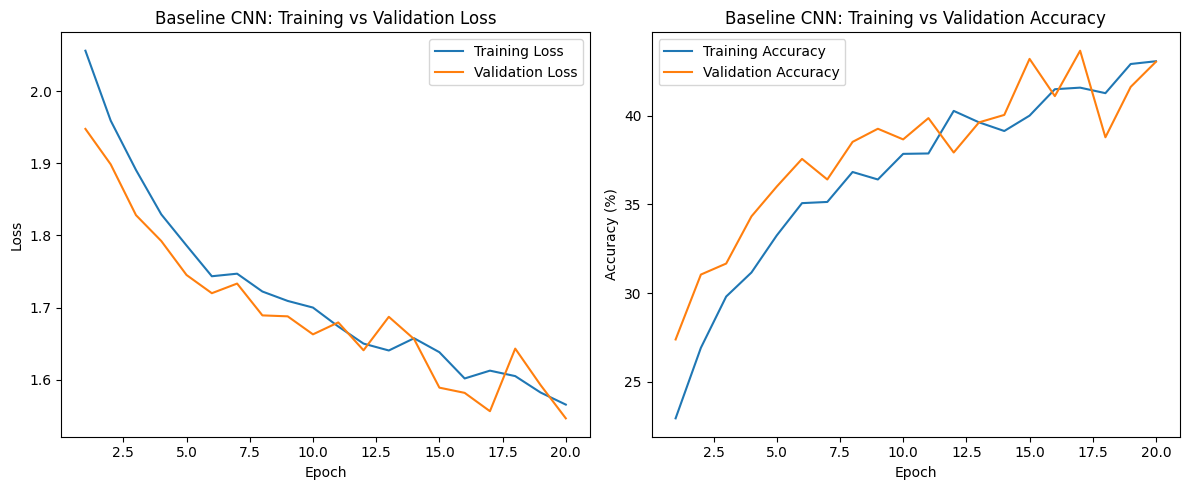

In [57]:
# Cell 93: Plot Baseline Training and Validation Curves

epochs = range(1, 21)

plt.figure(figsize=(12, 5))

# Plot training and validation loss
plt.subplot(1, 2, 1)
plt.plot(epochs, baseline_history["train_loss"], label="Training Loss")
plt.plot(epochs, baseline_history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN: Training vs Validation Loss")
plt.legend()

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, baseline_history["train_accuracy"], label="Training Accuracy")
plt.plot(epochs, baseline_history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Baseline CNN: Training vs Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [58]:
# Cell 94: Prepare CNN Without Dropout

set_seed(42)

overfit_cnn = SmallCNN().to(device)

# Turn off dropout to make overfitting easier to observe
overfit_cnn.dropout.p = 0.0

overfit_criterion = nn.CrossEntropyLoss()

overfit_optimizer = optim.Adam(
    overfit_cnn.parameters(),
    lr=0.001
)

print("CNN without dropout prepared!")
print("Training images:", len(resnet_small_train_loader.dataset))
print("Dropout probability:", overfit_cnn.dropout.p)

CNN without dropout prepared!
Training images: 4500
Dropout probability: 0.0


In [59]:
# Cell 95: Train CNN Without Dropout (20 Epochs)

overfit_history = train_cnn_experiment(
    overfit_cnn,
    resnet_small_train_loader,
    resnet_val_loader,
    overfit_criterion,
    overfit_optimizer,
    epochs=20,
    run_name="CNN_Without_Dropout"
)

print("Overfitting experiment complete!")

Epoch 1/20 | Train Loss: 1.9976 | Train Acc: 25.27% | Val Loss: 1.9194 | Val Acc: 29.48%
Epoch 2/20 | Train Loss: 1.8694 | Train Acc: 30.64% | Val Loss: 1.8529 | Val Acc: 31.46%
Epoch 3/20 | Train Loss: 1.7843 | Train Acc: 34.53% | Val Loss: 1.7663 | Val Acc: 35.38%
Epoch 4/20 | Train Loss: 1.7149 | Train Acc: 37.64% | Val Loss: 1.7143 | Val Acc: 37.24%
Epoch 5/20 | Train Loss: 1.6752 | Train Acc: 39.09% | Val Loss: 1.6920 | Val Acc: 38.48%
Epoch 6/20 | Train Loss: 1.6421 | Train Acc: 40.47% | Val Loss: 1.7438 | Val Acc: 37.20%
Epoch 7/20 | Train Loss: 1.6266 | Train Acc: 41.20% | Val Loss: 1.6967 | Val Acc: 39.06%
Epoch 8/20 | Train Loss: 1.5998 | Train Acc: 42.18% | Val Loss: 1.6492 | Val Acc: 37.22%
Epoch 9/20 | Train Loss: 1.5672 | Train Acc: 43.71% | Val Loss: 1.7054 | Val Acc: 38.96%
Epoch 10/20 | Train Loss: 1.5605 | Train Acc: 43.82% | Val Loss: 1.6049 | Val Acc: 42.48%
Epoch 11/20 | Train Loss: 1.5278 | Train Acc: 45.31% | Val Loss: 1.6074 | Val Acc: 42.10%
Epoch 12/20 | Train

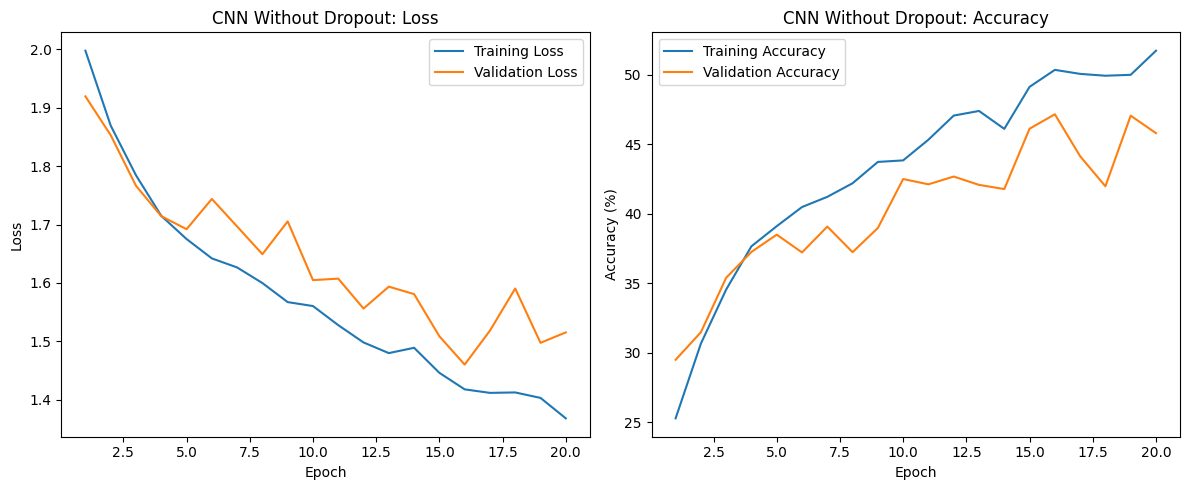

In [60]:
# Cell 96: Plot CNN Without Dropout Results

epochs = range(1, 21)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, overfit_history["train_loss"], label="Training Loss")
plt.plot(epochs, overfit_history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Without Dropout: Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, overfit_history["train_accuracy"], label="Training Accuracy")
plt.plot(epochs, overfit_history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Without Dropout: Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [61]:
# Cell 97: Prepare Data Augmentation

from copy import deepcopy
from torchvision import transforms

# Get the original training dataset and the same 10% subset indices
base_train_dataset = resnet_small_train_loader.dataset.dataset
subset_indices = resnet_small_train_loader.dataset.indices

# Create a copy with random cropping and horizontal flipping
augmented_dataset = deepcopy(base_train_dataset)
augmented_dataset.transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    base_train_dataset.transform
])

# Use the same 4,500 training images
augmented_subset = torch.utils.data.Subset(
    augmented_dataset, subset_indices
)

augmented_loader = torch.utils.data.DataLoader(
    augmented_subset, batch_size=64, shuffle=True
)

print("Augmented training dataset prepared!")
print("Training images:", len(augmented_subset))

Augmented training dataset prepared!
Training images: 4500


In [62]:
# Cell 98: Train CNN with Data Augmentation

set_seed(42)

augmented_cnn = SmallCNN().to(device)
augmented_cnn.dropout.p = 0.0

augmented_criterion = nn.CrossEntropyLoss()
augmented_optimizer = optim.Adam(
    augmented_cnn.parameters(), lr=0.001
)

augmented_history = train_cnn_experiment(
    augmented_cnn,
    augmented_loader,
    resnet_val_loader,
    augmented_criterion,
    augmented_optimizer,
    epochs=12,
    run_name="CNN_Data_Augmentation"
)

Epoch 1/12 | Train Loss: 2.0005 | Train Acc: 25.33% | Val Loss: 1.9576 | Val Acc: 26.82%
Epoch 2/12 | Train Loss: 1.9114 | Train Acc: 28.73% | Val Loss: 1.9271 | Val Acc: 27.22%
Epoch 3/12 | Train Loss: 1.8510 | Train Acc: 31.22% | Val Loss: 1.8263 | Val Acc: 31.96%
Epoch 4/12 | Train Loss: 1.7998 | Train Acc: 33.47% | Val Loss: 1.8226 | Val Acc: 33.44%
Epoch 5/12 | Train Loss: 1.7722 | Train Acc: 34.20% | Val Loss: 1.7882 | Val Acc: 35.24%
Epoch 6/12 | Train Loss: 1.7271 | Train Acc: 35.62% | Val Loss: 1.7951 | Val Acc: 33.36%
Epoch 7/12 | Train Loss: 1.7065 | Train Acc: 37.38% | Val Loss: 1.7865 | Val Acc: 34.96%
Epoch 8/12 | Train Loss: 1.6789 | Train Acc: 39.07% | Val Loss: 1.7309 | Val Acc: 36.34%
Epoch 9/12 | Train Loss: 1.6580 | Train Acc: 38.73% | Val Loss: 1.7380 | Val Acc: 38.16%
Epoch 10/12 | Train Loss: 1.6517 | Train Acc: 38.91% | Val Loss: 1.7305 | Val Acc: 36.66%
Epoch 11/12 | Train Loss: 1.6177 | Train Acc: 40.16% | Val Loss: 1.6685 | Val Acc: 38.52%
Epoch 12/12 | Train

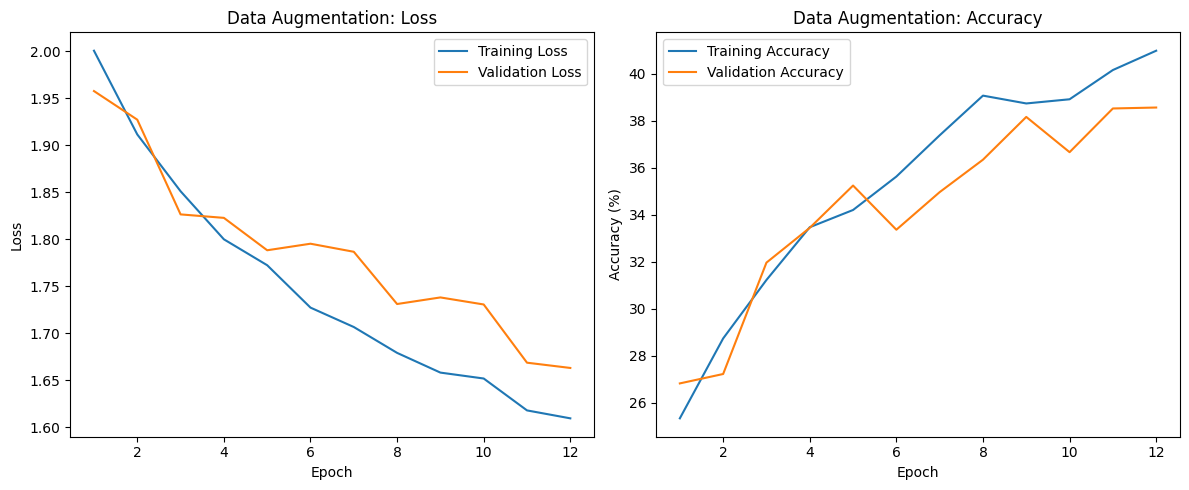

In [63]:
# Cell 99: Plot Data Augmentation Results

epochs = range(1, 13)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, augmented_history["train_loss"], label="Training Loss")
plt.plot(epochs, augmented_history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Data Augmentation: Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, augmented_history["train_accuracy"], label="Training Accuracy")
plt.plot(epochs, augmented_history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Data Augmentation: Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [64]:
# Cell 100: Prepare CNN with Weight Decay

set_seed(42)

weight_decay_cnn = SmallCNN().to(device)
weight_decay_cnn.dropout.p = 0.0

weight_decay_criterion = nn.CrossEntropyLoss()

weight_decay_optimizer = optim.Adam(
    weight_decay_cnn.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Weight decay CNN prepared!")
print("Weight decay:", 0.0001)
print("Training images:", len(resnet_small_train_loader.dataset))

Weight decay CNN prepared!
Weight decay: 0.0001
Training images: 4500


In [65]:
# Cell 101: Train CNN with Weight Decay

weight_decay_history = train_cnn_experiment(
    weight_decay_cnn,
    resnet_small_train_loader,
    resnet_val_loader,
    weight_decay_criterion,
    weight_decay_optimizer,
    epochs=12,
    run_name="CNN_Weight_Decay"
)

Epoch 1/12 | Train Loss: 1.9972 | Train Acc: 25.38% | Val Loss: 1.9281 | Val Acc: 29.16%
Epoch 2/12 | Train Loss: 1.8701 | Train Acc: 30.56% | Val Loss: 1.8579 | Val Acc: 31.50%
Epoch 3/12 | Train Loss: 1.7866 | Train Acc: 34.89% | Val Loss: 1.7771 | Val Acc: 34.82%
Epoch 4/12 | Train Loss: 1.7218 | Train Acc: 37.02% | Val Loss: 1.7051 | Val Acc: 37.20%
Epoch 5/12 | Train Loss: 1.6763 | Train Acc: 39.24% | Val Loss: 1.6916 | Val Acc: 38.10%
Epoch 6/12 | Train Loss: 1.6473 | Train Acc: 40.36% | Val Loss: 1.7219 | Val Acc: 37.40%
Epoch 7/12 | Train Loss: 1.6301 | Train Acc: 40.51% | Val Loss: 1.7002 | Val Acc: 40.28%
Epoch 8/12 | Train Loss: 1.6034 | Train Acc: 42.18% | Val Loss: 1.6464 | Val Acc: 37.76%
Epoch 9/12 | Train Loss: 1.5719 | Train Acc: 43.24% | Val Loss: 1.7253 | Val Acc: 38.12%
Epoch 10/12 | Train Loss: 1.5681 | Train Acc: 43.44% | Val Loss: 1.6116 | Val Acc: 40.92%
Epoch 11/12 | Train Loss: 1.5319 | Train Acc: 44.80% | Val Loss: 1.6013 | Val Acc: 42.24%
Epoch 12/12 | Train

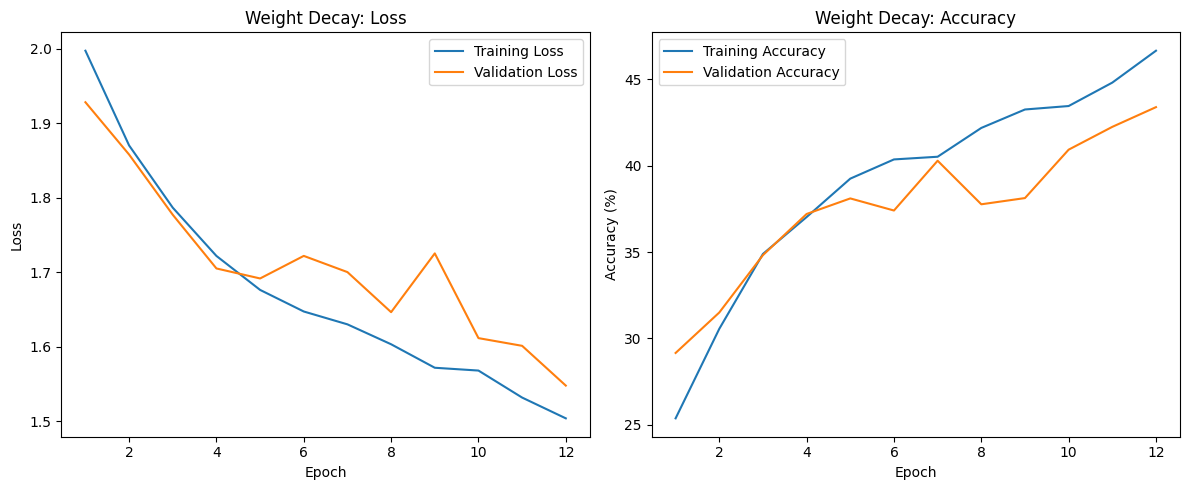

In [66]:
# Cell 102: Plot Weight Decay Results

epochs = range(1, 13)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, weight_decay_history["train_loss"], label="Training Loss")
plt.plot(epochs, weight_decay_history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Weight Decay: Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, weight_decay_history["train_accuracy"], label="Training Accuracy")
plt.plot(epochs, weight_decay_history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Weight Decay: Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [67]:
# Cell 103: Train CNN with Early Stopping

set_seed(42)

early_stop_cnn = SmallCNN().to(device)
early_stop_cnn.dropout.p = 0.0

early_stop_criterion = nn.CrossEntropyLoss()
early_stop_optimizer = optim.Adam(
    early_stop_cnn.parameters(), lr=0.001
)

early_stop_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
patience = 3
epochs_without_improvement = 0
best_model_state = None

for epoch in range(12):
    early_stop_cnn.train()
    train_loss_total = 0
    train_correct = 0
    train_total = 0

    for images, labels in resnet_small_train_loader:
        images, labels = images.to(device), labels.to(device)

        early_stop_optimizer.zero_grad()
        outputs = early_stop_cnn(images)
        loss = early_stop_criterion(outputs, labels)
        loss.backward()
        early_stop_optimizer.step()

        train_loss_total += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_total / train_total
    train_accuracy = 100 * train_correct / train_total

    early_stop_cnn.eval()
    val_loss_total = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in resnet_val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = early_stop_cnn(images)
            loss = early_stop_criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_accuracy = 100 * val_correct / val_total

    early_stop_history["train_loss"].append(train_loss)
    early_stop_history["train_accuracy"].append(train_accuracy)
    early_stop_history["val_loss"].append(val_loss)
    early_stop_history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/12 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = deepcopy(early_stop_cnn.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered!")
        break

early_stop_cnn.load_state_dict(best_model_state)
print("Early stopping experiment complete!")
print("Best validation loss:", round(best_val_loss, 4))
print("Epochs completed:", len(early_stop_history["val_loss"]))

Epoch 1/12 | Train Loss: 1.9976 | Train Acc: 25.27% | Val Loss: 1.9192 | Val Acc: 29.52%
Epoch 2/12 | Train Loss: 1.8695 | Train Acc: 30.60% | Val Loss: 1.8573 | Val Acc: 30.98%
Epoch 3/12 | Train Loss: 1.7851 | Train Acc: 34.11% | Val Loss: 1.7838 | Val Acc: 34.28%
Epoch 4/12 | Train Loss: 1.7186 | Train Acc: 37.29% | Val Loss: 1.7115 | Val Acc: 37.74%
Epoch 5/12 | Train Loss: 1.6733 | Train Acc: 39.44% | Val Loss: 1.6990 | Val Acc: 37.94%
Epoch 6/12 | Train Loss: 1.6439 | Train Acc: 40.38% | Val Loss: 1.7292 | Val Acc: 37.74%
Epoch 7/12 | Train Loss: 1.6258 | Train Acc: 41.00% | Val Loss: 1.6897 | Val Acc: 40.38%
Epoch 8/12 | Train Loss: 1.5937 | Train Acc: 41.93% | Val Loss: 1.6136 | Val Acc: 39.52%
Epoch 9/12 | Train Loss: 1.5670 | Train Acc: 43.31% | Val Loss: 1.7332 | Val Acc: 38.28%
Epoch 10/12 | Train Loss: 1.5606 | Train Acc: 43.71% | Val Loss: 1.5984 | Val Acc: 41.92%
Epoch 11/12 | Train Loss: 1.5251 | Train Acc: 45.42% | Val Loss: 1.6109 | Val Acc: 42.02%
Epoch 12/12 | Train

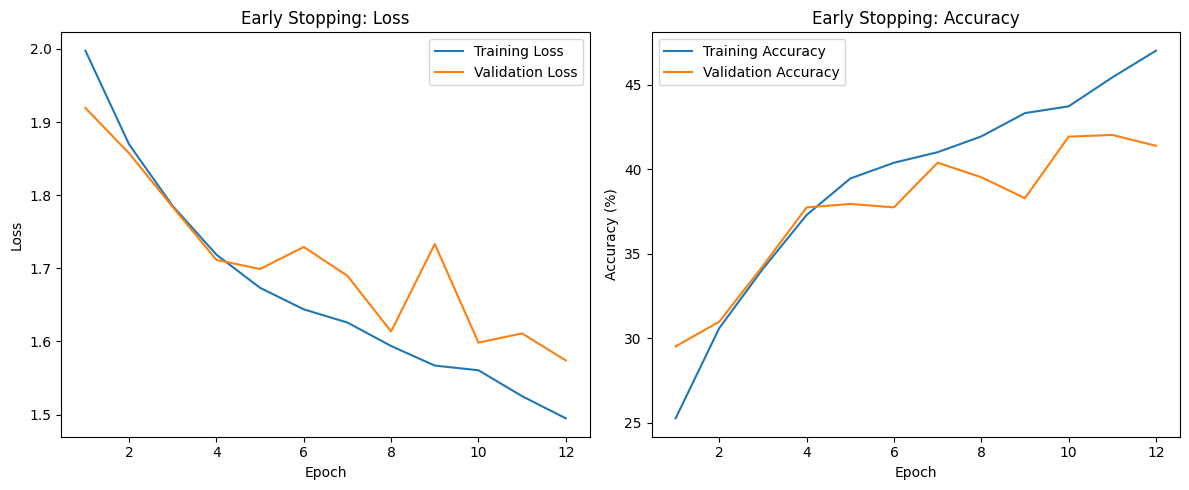

In [68]:
# Cell 104: Plot Early Stopping Results

epochs = range(1, len(early_stop_history["train_loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, early_stop_history["train_loss"], label="Training Loss")
plt.plot(epochs, early_stop_history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Early Stopping: Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, early_stop_history["train_accuracy"], label="Training Accuracy")
plt.plot(epochs, early_stop_history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Early Stopping: Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

## Final Comparison: Overfitting and Regularization

### Results

The following table compares the final training and validation accuracy for each experiment.

| Experiment | Training Accuracy | Validation Accuracy |
|---|---:|---:|
| Baseline CNN (without dropout) | 51.71% | 45.78% |
| Data Augmentation | 40.98% | 38.56% |
| Weight Decay | 46.64% | 43.38% |
| Early Stopping | 47.00% | 41.38% |

### Analysis of Regularization Techniques

**1. Data Augmentation**

Data augmentation uses random cropping and horizontal flipping to create slightly different versions of training images. This encourages the model to learn general features instead of memorizing specific images. In my experiment, the training and validation accuracies were closer together, suggesting a smaller generalization gap. However, overall accuracy was also lower, meaning the model may have been learning more slowly.

**2. Weight Decay**

Weight decay adds a penalty for large model weights during training. This discourages the model from becoming overly dependent on particular features and can reduce overfitting. In my experiment, the final training accuracy was 46.64% and validation accuracy was 43.38%. The relatively small gap suggests that weight decay helped keep the model's performance on training and validation data closer together.

**3. Early Stopping**

Early stopping monitors validation loss and saves the model whenever validation loss improves. It is designed to stop training before the model begins overfitting. In my experiment, the validation loss continued to reach new best values, so the stopping condition was not triggered within the 12 epochs. This shows that early stopping did not shorten training in